In [133]:

# ============================================================
# CELL 1: IMPORT LIBRARIES
# ============================================================

import os
import re
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Libraries imported successfully.")


Libraries imported successfully.


In [134]:

# ============================================================
# CELL 2: MODEL SETTINGS
# ============================================================

MODEL_NAME = "HiMCM Hierarchical Livability MCDA"

# Number of countries and regions advanced to the next tier.
# Change these values to test different screening sizes.
COUNTRIES_TO_ADVANCE = 20
REGIONS_PER_COUNTRY_TO_ADVANCE = 10

# Minimum weighted data coverage required for a location
# to receive a final score.
MIN_DATA_COVERAGE = 0.50

# Small value used to prevent log(0) in entropy calculations.
EPSILON = 1e-12

# Number of Monte Carlo sensitivity simulations.
N_SIMULATIONS = 1000

# Random seed for reproducibility.
RANDOM_SEED = 42

print(MODEL_NAME)
print("Countries advanced:", COUNTRIES_TO_ADVANCE)
print("Regions advanced per country:", REGIONS_PER_COUNTRY_TO_ADVANCE)
print("Minimum data coverage:", MIN_DATA_COVERAGE)


HiMCM Hierarchical Livability MCDA
Countries advanced: 20
Regions advanced per country: 10
Minimum data coverage: 0.5


In [135]:

# ============================================================
# CELL 3: LOAD ALL UPLOADED DATASETS
# ============================================================

from google.colab import files

# Optional upload prompt:
# If your files are already uploaded, you can skip this line.
# uploaded = files.upload()

FILE_REGISTRY = {
    "tier1": {
        "urban_basic_services": {
            "file": "Population_with_Improved_Water__Sanitation_and_Other_Urban_Basic_Services_in_Urban_Areas__Selected_Countries_(Percent) (1).xlsx - 2-Data.csv",
            "type": "csv",
            "sheet": "2-Data"
        },
        "drinking_water": {
            "file": "People using at least basic drinking water services (_ of population) - Sheet1.csv",
            "type": "csv"
        },
        "cpi": {
            "file": "CPI 2016.csv",
            "type": "csv"
        },
        "table25": {
            "file": "table25.csv",
            "type": "csv"
        },
        "service_coverage": {
            "file": "Percentage Service Coverage.csv",
            "type": "csv"
        },
        "gini": {
            "file": "Gini_at_disposable_income_after_taxes_and_transfers,_2010_-_2017.xls - Sheet1.csv",
            "type": "csv"
        },
        "sanitation": {
            "file": "Percentage of Country using basic sanitations services   - Sheet1.csv",
            "type": "csv"
        }
    },

    "tier2": {
        "homicide_1": {
            "file": "Intentional homicides (per 100,000 people) - Sheet1 (1).csv",
            "type": "csv"
        },
        "aqi": {
            "file": "AQI and Lat Long of Countries.csv",
            "type": "csv"
        },
        "public_space": {
            "file": "SDG_11.7.1_July_2026.csv",
            "type": "csv"
        },
        "corruption_crime": {
            "file": "data_cts_corruption_and_economic_crime (1).xlsx - data_cts_corruption_and_economi.csv",
            "type": "csv"
        },
        "violent_crime": {
            "file": "data_cts_violent_and_sexual_crime (1).xlsx - data_cts_violent_and_sexual_cri.csv",
            "type": "csv"
        },
        "public_transport": {
            "file": "SDG_11.2.1_July_2026.csv",
            "type": "csv"
        },
        "human_capital": {
            "file": "WB_HCP_TEST.csv",
            "type": "csv"
        },
        "pm25": {
            "file": "Mean_Population_Exposure_to_PM2.5_by_Country,_2015_-_2019.xls - Data.csv",
            "type": "csv"
        },
        "homicide_2": {
            "file": "Intentional homicides (per 100,000 people) - Sheet1.csv",
            "type": "csv"
        },
        "higher_education": {
            "file": "Attained higher Ed percentage.csv",
            "type": "csv"
        }
    }
}


def load_dataset(file_info):
    filename = file_info["file"]

    if not os.path.exists(filename):
        print(f"NOT FOUND: {filename}")
        return None

    if file_info["type"] == "excel":
        return pd.read_excel(
            filename,
            sheet_name=file_info.get("sheet", 0)
        )

    if file_info["type"] == "csv":
        return pd.read_csv(filename, low_memory=False)

    raise ValueError(f"Unsupported file type: {file_info['type']}")


DATASETS = {}

for tier, datasets in FILE_REGISTRY.items():
    DATASETS[tier] = {}

    for dataset_name, file_info in datasets.items():
        DATASETS[tier][dataset_name] = load_dataset(file_info)


print("\nDATASET LOADING SUMMARY")

for tier, datasets in DATASETS.items():
    print(f"\n{tier.upper()}")

    for name, df in datasets.items():
        if df is None:
            print(f"{name}: MISSING")
        else:
            print(f"{name}: {df.shape[0]} rows × {df.shape[1]} columns")

print("\nLoading complete.")



DATASET LOADING SUMMARY

TIER1
urban_basic_services: 17094 rows × 61 columns
drinking_water: 644 rows × 1 columns
cpi: 351 rows × 35 columns
table25: 511 rows × 1 columns
service_coverage: 271 rows × 16 columns
gini: 228 rows × 10 columns
sanitation: 644 rows × 1 columns

TIER2
homicide_1: 608 rows × 1 columns
aqi: 16695 rows × 14 columns
public_space: 3663 rows × 15 columns
corruption_crime: 27081 rows × 13 columns
violent_crime: 34976 rows × 13 columns
public_transport: 2927 rows × 14 columns
human_capital: 1727 rows × 41 columns
pm25: 2686 rows × 8 columns
homicide_2: 608 rows × 1 columns
higher_education: 271 rows × 16 columns

Loading complete.


In [136]:

# ============================================================
# CELL 4: INSPECT DATASET COLUMNS AND SAMPLE RECORDS
# ============================================================

for tier, datasets in DATASETS.items():

    print("\n" + "=" * 90)
    print(tier.upper())
    print("=" * 90)

    for name, df in datasets.items():

        if df is None:
            continue

        print("\nDATASET:", name)
        print("COLUMNS:", list(df.columns))
        print("SHAPE:", df.shape)

        display(df.head(3))



TIER1

DATASET: urban_basic_services
COLUMNS: ['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Unnamed: 32', 'Unnamed: 33', 'Unnamed: 34', 'Unnamed: 35', 'Unnamed: 36', 'Unnamed: 37', 'Unnamed: 38', 'Unnamed: 39', 'Unnamed: 40', 'Unnamed: 41', 'Unnamed: 42', 'Unnamed: 43', 'Unnamed: 44', 'Unnamed: 45', 'Unnamed: 46', 'Unnamed: 47', 'Unnamed: 48', 'Unnamed: 49', 'Unnamed: 50', 'Unnamed: 51', 'Unnamed: 52', 'Unnamed: 53', 'Unnamed: 54', 'Unnamed: 55', 'Unnamed: 56', 'Unnamed: 57', 'Unnamed: 58', 'Unnamed: 59', 'Unnamed: 60']
SHAPE: (17094, 61)


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31,Unnamed: 32,Unnamed: 33,Unnamed: 34,Unnamed: 35,Unnamed: 36,Unnamed: 37,Unnamed: 38,Unnamed: 39,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Unnamed: 47,Unnamed: 48,Unnamed: 49,Unnamed: 50,Unnamed: 51,Unnamed: 52,Unnamed: 53,Unnamed: 54,Unnamed: 55,Unnamed: 56,Unnamed: 57,Unnamed: 58,Unnamed: 59,Unnamed: 60
0,NaN,NaN,NaN,UN-Habitat\n(United Nations Human Settlements ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



DATASET: drinking_water
COLUMNS: ['Afghanistan']
SHAPE: (644, 1)


,Afghanistan
0,2024
1,81
2,Albania



DATASET: cpi
COLUMNS: ['Table 4: City Prosperity Index. Global CPI. Base Data. 2016 ', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Unnamed: 32', 'Unnamed: 33', 'Unnamed: 34']
SHAPE: (351, 35)


,Table 4: City Prosperity Index. Global CPI. Base Data. 2016,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31,Unnamed: 32,Unnamed: 33,Unnamed: 34
0,City Prosperity Index. Global CPI. Base Data. ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,COUNTRY,METROPOLITAN AREA,CITY,YEAR,NaN,PRODUCTIVITY INDEX (P),NaN,NaN,INFRASTRUCTURE DEVELOPMENT INDEX (ID),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,QUALITY OF LIFE INDEX (QOL),NaN,NaN,NaN,NaN,NaN,EQUITY AND SOCIAL INCLUSION INDEX (ESI),NaN,NaN,NaN,NaN,NaN,ENVIRONMENTAL SUSTAINABILITY,NaN,NaN,NaN,NaN,URBAN GOVERNANCE AND LEGISLATION INDEX (GI)
2,NaN,NaN,NaN,NaN,NaN,Economic Strenght,Employment,NaN,Housing Infrastructure,NaN,NaN,Social Infrastructure,ICT,Urban Mobility,NaN,NaN,NaN,Health,NaN,Education,NaN,Security,NaN,Economic Equity,NaN,Social Inclusion,NaN,Gender Inclusion,NaN,Air Quality,NaN,Water and Energy,NaN,NaN,Participation and Accountability


... (24 outputs left out)


DATASET: homicide_2
COLUMNS: ['Afghanistan']
SHAPE: (608, 1)


,Afghanistan
0,2021
1,4
2,Albania



DATASET: higher_education
COLUMNS: ['Series Name', 'Series Code', 'Country Name', 'Country Code', '1990 [YR1990]', '2000 [YR2000]', '2016 [YR2016]', '2017 [YR2017]', '2018 [YR2018]', '2019 [YR2019]', '2020 [YR2020]', '2021 [YR2021]', '2022 [YR2022]', '2023 [YR2023]', '2024 [YR2024]', '2025 [YR2025]']
SHAPE: (271, 16)


,Series Name,Series Code,Country Name,Country Code,1990 [YR1990],2000 [YR2000],2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
0,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,Afghanistan,AFG,..,..,..,5.26141700354864,..,..,3.71811698299556,3.06798005104065,3.98425006866455,..,..,..
1,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,Albania,ALB,..,..,14.3157503195291,16.1501998901367,16.4676840857403,17.3219430335689,17.804132917267,18.2029345963076,19.8346436163563,17.5054893493652,..,..
2,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,Algeria,DZA,..,..,..,..,..,11.4359302520752,..,..,..,..,..,..


In [137]:

# ============================================================
# CELL 5: WORLD BANK API
# ============================================================

WORLD_BANK_BASE_URL = "https://api.worldbank.org/v2"

WORLD_BANK_INDICATORS = {
    "population": "SP.POP.TOTL",
    "drinking_water": "SH.H2O.BASW.ZS",
    "sanitation": "SH.STA.BASS.ZS",
    "gini": "SI.POV.GINI",
    "homicide": "VC.IHR.PSRC.P5",
    "pm25": "EN.ATM.PM25.MC.M3"
}


def get_world_bank_indicator(indicator_code, start_year=2010, end_year=2025):

    url = (
        f"{WORLD_BANK_BASE_URL}/country/all/indicator/"
        f"{indicator_code}"
    )

    params = {
        "format": "json",
        "per_page": 20000,
        "date": f"{start_year}:{end_year}"
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    result = response.json()

    if not isinstance(result, list) or len(result) < 2:
        print("No data returned for:", indicator_code)
        return pd.DataFrame()

    records = result[1]

    if records is None:
        return pd.DataFrame()

    rows = []

    for record in records:

        region = record.get("region", {}) or {}

        # Remove World Bank aggregate regions.
        if region.get("value") == "Aggregates":
            continue

        rows.append({
            "country": (record.get("country") or {}).get("value"),
            "iso3": record.get("countryiso3code"),
            "year": record.get("date"),
            "indicator_code": indicator_code,
            "value": record.get("value")
        })

    df = pd.DataFrame(rows)

    if not df.empty:
        df["value"] = pd.to_numeric(df["value"], errors="coerce")
        df["year"] = pd.to_numeric(df["year"], errors="coerce")

    return df


WORLD_BANK_DATA = {}

for indicator_name, indicator_code in WORLD_BANK_INDICATORS.items():

    try:
        df = get_world_bank_indicator(indicator_code)

        WORLD_BANK_DATA[indicator_name] = df

        print(
            indicator_name,
            indicator_code,
            "records:",
            len(df)
        )

    except Exception as error:
        print("API error:", indicator_name, error)
        WORLD_BANK_DATA[indicator_name] = pd.DataFrame()


print("\nWorld Bank retrieval complete.")


population SP.POP.TOTL records: 4256
drinking_water SH.H2O.BASW.ZS records: 4256
sanitation SH.STA.BASS.ZS records: 4256
gini SI.POV.GINI records: 4256
homicide VC.IHR.PSRC.P5 records: 4256
pm25 EN.ATM.PM25.MC.M3 records: 4256

World Bank retrieval complete.


In [138]:

# ============================================================
# CELL 6: CRITERIA CONFIGURATION
# ============================================================

# Each criterion has:
# - tier
# - category
# - direction
# - source dataset
# - source column (to be completed after inspecting Cell 4)
# - geographic level

CRITERIA = {

    # ---------------- TIER 1: COUNTRIES ----------------

    "urban_basic_services": {
        "tier": "tier1",
        "category": "Infrastructure",
        "direction": "benefit",
        "dataset": "urban_basic_services",
        "column": None,
        "location_column": None,
        "geographic_level": "country"
    },

    "drinking_water": {
        "tier": "tier1",
        "category": "Infrastructure",
        "direction": "benefit",
        "dataset": "drinking_water",
        "column": None,
        "location_column": None,
        "geographic_level": "country"
    },

    "sanitation": {
        "tier": "tier1",
        "category": "Infrastructure",
        "direction": "benefit",
        "dataset": "sanitation",
        "column": None,
        "location_column": None,
        "geographic_level": "country"
    },

    "gini": {
        "tier": "tier1",
        "category": "Economic_Equality",
        "direction": "cost",
        "dataset": "gini",
        "column": None,
        "location_column": None,
        "geographic_level": "country"
    },

    "cpi": {
        "tier": "tier1",
        "category": "Governance",
        # If this is Transparency International's CPI:
        # higher scores mean cleaner public sectors.
        "direction": "benefit",
        "dataset": "cpi",
        "column": None,
        "location_column": None,
        "geographic_level": "country"
    },

    "service_coverage": {
        "tier": "tier1",
        "category": "Healthcare",
        "direction": "benefit",
        "dataset": "service_coverage",
        "column": None,
        "location_column": None,
        "geographic_level": "country"
    },

    "table25_indicator": {
        "tier": "tier1",
        "category": "Other",
        "direction": "benefit",
        "dataset": "table25",
        "column": None,
        "location_column": None,
        "geographic_level": "country"
    },


    # ---------------- TIER 2: REGIONS / URBAN AREAS ----------------

    "homicide": {
        "tier": "tier2",
        "category": "Safety",
        "direction": "cost",
        "dataset": "homicide_1",
        "column": None,
        "location_column": None,
        "geographic_level": "region"
    },

    "aqi": {
        "tier": "tier2",
        "category": "Environment",
        "direction": "cost",
        "dataset": "aqi",
        "column": None,
        "location_column": None,
        "geographic_level": "region"
    },

    "public_space": {
        "tier": "tier2",
        "category": "Public_Infrastructure",
        "direction": "benefit",
        "dataset": "public_space",
        "column": None,
        "location_column": None,
        "geographic_level": "region"
    },

    "corruption_crime": {
        "tier": "tier2",
        "category": "Governance",
        "direction": "cost",
        "dataset": "corruption_crime",
        "column": None,
        "location_column": None,
        "geographic_level": "region"
    },

    "violent_crime": {
        "tier": "tier2",
        "category": "Safety",
        "direction": "cost",
        "dataset": "violent_crime",
        "column": None,
        "location_column": None,
        "geographic_level": "region"
    },

    "public_transport": {
        "tier": "tier2",
        "category": "Public_Infrastructure",
        "direction": "benefit",
        "dataset": "public_transport",
        "column": None,
        "location_column": None,
        "geographic_level": "region"
    },

    "human_capital": {
        "tier": "tier2",
        "category": "Education_Health",
        "direction": "benefit",
        "dataset": "human_capital",
        "column": None,
        "location_column": None,
        "geographic_level": "region"
    },

    "pm25": {
        "tier": "tier2",
        "category": "Environment",
        "direction": "cost",
        "dataset": "pm25",
        "column": None,
        "location_column": None,
        "geographic_level": "region"
    },

    "higher_education": {
        "tier": "tier2",
        "category": "Education_Health",
        "direction": "benefit",
        "dataset": "higher_education",
        "column": None,
        "location_column": None,
        "geographic_level": "region"
    }

}


# Do not include homicide_2 separately yet.
# It may duplicate homicide_1. Compare the two files before deciding.

print("Number of configured criteria:", len(CRITERIA))


Number of configured criteria: 16


In [139]:

# ============================================================
# CELL 6.5: DATASET AND FILE DIAGNOSTICS
# ============================================================

import os

print("FILES AVAILABLE IN GOOGLE COLAB:")
for filename in sorted(os.listdir("/content")):
    if filename.lower().endswith((".csv", ".xlsx", ".xls")):
        print(" -", filename)

print("\nDATASETS CURRENTLY LOADED:")

for tier, datasets in DATASETS.items():
    print(f"\n{tier.upper()}")

    for name, df in datasets.items():
        if df is None:
            print(f"  ERROR: {name} was NOT loaded")
        else:
            print(f"  LOADED: {name} | {df.shape[0]} rows | {df.shape[1]} columns")

print("\nCRITERIA CONFIGURATION:")

for indicator, config in CRITERIA.items():
    print(
        indicator,
        "| Tier:", config.get("tier"),
        "| Dataset:", config.get("dataset"),
        "| Value column:", config.get("column"),
        "| Location column:", config.get("location_column")
    )


FILES AVAILABLE IN GOOGLE COLAB:
 -  SDG_11.7.1_July_2026.csv
 - AQI and Lat Long of Countries.csv
 - All_Tier_2_Regions.csv
 - Attained higher Ed percentage.csv
 - CPI 2016.csv
 - Gini_at_disposable_income_after_taxes_and_transfers,_2010_-_2017.xls - Sheet1.csv
 - HiMCM_Regional_Boundaries.csv
 - HiMCM_Tier2_All_Country_Scores.csv
 - HiMCM_Tier2_COMPLETE_PM25_RANKING.csv
 - HiMCM_Tier2_Category_Weights.csv
 - HiMCM_Tier2_Criterion_Weights.csv
 - HiMCM_Tier2_Final_Rankings.csv
 - HiMCM_Tier2_PM25_Coverage.csv
 - HiMCM_Tier2_PM25_Regional_Matches.csv
 - HiMCM_Tier2_Sensitivity_Analysis.csv
 - Intentional homicides (per 100,000 people) - Sheet1 (1).csv
 - Intentional homicides (per 100,000 people) - Sheet1.csv
 - Mean_Population_Exposure_to_PM2.5_by_Country,_2015_-_2019.xls - Data.csv
 - People using at least basic drinking water services (_ of population) - Sheet1.csv
 - Percentage Service Coverage.csv
 - Percentage of Country using basic sanitations services   - Sheet1.csv
 - Populatio

In [140]:

# ============================================================
# CELL 7: STANDARDIZE ALL CSV DATASETS
# ============================================================

import pandas as pd
import numpy as np
import re
import warnings

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. HELPER FUNCTIONS
# ------------------------------------------------------------

def normalize_name(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())


def normalize_tier(tier):
    tier = str(tier).lower().replace(" ", "").replace("_", "")

    if "tier1" in tier:
        return "tier1"
    elif "tier2" in tier:
        return "tier2"
    elif "tier3" in tier:
        return "tier3"

    raise ValueError(f"Unknown tier: {tier}")


# ------------------------------------------------------------
# 2. DETECT AND REPAIR CSV HEADERS
# ------------------------------------------------------------

def repair_csv_header(df, max_rows=30):

    df = df.copy()

    # If headers already exist, retain them.
    if not all(
        str(c).lower().startswith("unnamed")
        for c in df.columns
    ):
        return df

    best_row = None
    best_score = -1

    keywords = [
        "country", "location", "city", "region",
        "year", "urban", "water", "sanitation",
        "population", "indicator", "service",
        "percentage", "geoarea"
    ]

    # Search the first 30 rows for the actual header.
    for i in range(min(max_rows, len(df))):

        row = df.iloc[i]

        values = [
            str(x).strip()
            for x in row
            if pd.notna(x) and str(x).strip()
        ]

        joined = " ".join(values).lower()

        score = len(values)

        score += sum(
            keyword in joined
            for keyword in keywords
        ) * 5

        if score > best_score:
            best_score = score
            best_row = i

    if best_row is None or best_score < 2:
        raise ValueError(
            "Could not locate the CSV header row."
        )

    # Use the detected row as the new header.
    headers = []

    for value in df.iloc[best_row]:

        if pd.isna(value) or str(value).strip() == "":
            headers.append("unnamed")
        else:
            headers.append(str(value).strip())

    df = df.iloc[best_row + 1:].copy()
    df.columns = headers

    # Remove completely empty columns.
    df = df.dropna(axis=1, how="all")

    # Remove completely empty rows.
    df = df.dropna(axis=0, how="all")

    print(f"  CSV header detected at row {best_row + 1}")

    return df.reset_index(drop=True)


# ------------------------------------------------------------
# 3. IDENTIFY GEOGRAPHIC LOCATION COLUMN
# ------------------------------------------------------------

def find_location_column(df):

    keywords = [
        "country", "countryname",
        "location", "city", "cityname",
        "region", "regionname",
        "geoarea", "geographicarea",
        "urbanarea", "municipality",
        "province", "state", "place"
    ]

    matches = []

    for column in df.columns:

        name = normalize_name(column)

        if any(keyword in name for keyword in keywords):
            matches.append(column)

    preferred = [
        "country", "countryname",
        "location", "city", "cityname",
        "region", "regionname", "geoarea"
    ]

    for preferred_name in preferred:

        for column in matches:

            if normalize_name(column) == preferred_name:
                return column

    if len(matches) == 1:
        return matches[0]

    if len(matches) == 0:

        raise ValueError(
            "No geographic column identified. "
            f"Available columns: {list(df.columns)}"
        )

    raise ValueError(
        f"Multiple geographic columns found: {matches}. "
        "Set location_column in Cell 6."
    )


# ------------------------------------------------------------
# 4. IDENTIFY NUMERIC INDICATOR COLUMNS
# ------------------------------------------------------------

def find_value_columns(df, location_column):

    excluded = [
        "latitude", "longitude",
        "lat", "long", "id",
        "code", "rank"
    ]

    candidates = []

    for column in df.columns:

        if column == location_column:
            continue

        name = normalize_name(column)

        # Exclude geographic coordinates and identifiers.
        if any(name == x or name.startswith(x) for x in excluded):
            continue

        numeric = pd.to_numeric(
            df[column].astype(str).str.replace(",", "", regex=False),
            errors="coerce"
        )

        if numeric.notna().sum() > 0:
            candidates.append(column)

    if len(candidates) == 0:
        raise ValueError("No numeric indicator columns found.")

    return candidates


# ------------------------------------------------------------
# 5. RETRIEVE DATASETS
# ------------------------------------------------------------

def get_dataset(tier, dataset_name):

    tier_key = normalize_tier(tier)

    if tier_key not in DATASETS:
        raise KeyError(f"Tier not found: {tier_key}")

    if dataset_name not in DATASETS[tier_key]:
        raise KeyError(f"Dataset not found: {dataset_name}")

    df = DATASETS[tier_key][dataset_name]

    if df is None:
        raise ValueError(
            f"{dataset_name} was not loaded. "
            "Check Cell 1 and the CSV filename."
        )

    return df.copy()


# ------------------------------------------------------------
# 6. STANDARDIZE ALL CRITERIA
# ------------------------------------------------------------

STANDARDIZED_DATA = []
MAPPING_REPORT = []
DATA_ERRORS = []

for indicator, config in CRITERIA.items():

    print(f"\nProcessing: {indicator}")

    try:

        df = get_dataset(
            config["tier"],
            config["dataset"]
        )

        # Repair CSV headers when necessary.
        df = repair_csv_header(df)

        # Retrieve Cell 6 mappings.
        location_column = config.get("location_column")
        value_column = config.get("column")

        # Automatically identify location.
        if location_column is None:
            location_column = find_location_column(df)

        if location_column not in df.columns:
            raise ValueError(
                f"Location column '{location_column}' not found. "
                f"Available columns: {list(df.columns)}"
            )

        # Identify value columns.
        if value_column is None:

            value_columns = find_value_columns(
                df,
                location_column
            )

        else:

            if value_column not in df.columns:
                raise ValueError(
                    f"Value column '{value_column}' not found."
                )

            value_columns = [value_column]

        # ----------------------------------------------------
        # RESHAPE WIDE-FORMAT DATA
        # ----------------------------------------------------

        year_columns = []

        for column in value_columns:

            match = re.search(r"(?:19|20)\d{2}", str(column))

            if match:
                year_columns.append((column, match.group()))

        if len(value_columns) == 1:

            temp = df[
                [location_column, value_columns[0]]
            ].copy()

            temp.columns = ["location", "value"]
            temp["year"] = np.nan

        elif len(year_columns) == len(value_columns):

            temp = df.melt(
                id_vars=[location_column],
                value_vars=value_columns,
                var_name="source_year",
                value_name="value"
            )

            temp["year"] = temp["source_year"].str.extract(
                r"((?:19|20)\d{2})"
            )

            temp = temp.rename(
                columns={location_column: "location"}
            )

        else:

            raise ValueError(
                f"Multiple numeric columns found: {value_columns}. "
                "Specify the correct value column in Cell 6, "
                "or configure the dataset's year columns."
            )

        # ----------------------------------------------------
        # CLEAN OBSERVATIONS
        # ----------------------------------------------------

        temp["location"] = (
            temp["location"]
            .astype("string")
            .str.strip()
        )

        temp["value"] = pd.to_numeric(
            temp["value"].astype(str).str.replace(",", "", regex=False),
            errors="coerce"
        )

        temp = temp.dropna(
            subset=["location", "value"]
        )

        temp = temp[
            temp["location"].str.len() > 0
        ]

        # ----------------------------------------------------
        # ADD METADATA
        # ----------------------------------------------------

        temp["indicator"] = indicator
        temp["tier"] = normalize_tier(config["tier"])
        temp["category"] = config["category"]
        temp["direction"] = config["direction"]
        temp["geographic_level"] = config["geographic_level"]

        STANDARDIZED_DATA.append(temp)

        MAPPING_REPORT.append({
            "indicator": indicator,
            "dataset": config["dataset"],
            "location_column": location_column,
            "value_columns": value_columns,
            "observations": len(temp),
            "years": temp["year"].nunique()
        })

        print("  SUCCESS")
        print("  Location:", location_column)
        print("  Values:", value_columns)
        print("  Observations:", len(temp))

    except Exception as error:

        DATA_ERRORS.append({
            "indicator": indicator,
            "dataset": config.get("dataset"),
            "error": str(error)
        })

        print("  ERROR:", error)


# ------------------------------------------------------------
# 7. COMBINE STANDARDIZED DATASETS
# ------------------------------------------------------------

if not STANDARDIZED_DATA:

    raise ValueError(
        "No datasets were standardized. "
        "Review DATA_ERRORS."
    )

LONG_DATA = pd.concat(
    STANDARDIZED_DATA,
    ignore_index=True
)

# ------------------------------------------------------------
# 8. FINAL REPORT
# ------------------------------------------------------------

MAPPING_REPORT = pd.DataFrame(MAPPING_REPORT)
DATA_ERRORS = pd.DataFrame(DATA_ERRORS)

print("\n" + "=" * 65)
print("CELL 7 COMPLETE")
print("=" * 65)

print("Indicators standardized:",
      LONG_DATA["indicator"].nunique())

print("Total observations:",
      len(LONG_DATA))

print("Unique locations:",
      LONG_DATA["location"].nunique())

print("\nMAPPING REPORT:")
display(MAPPING_REPORT)

if not DATA_ERRORS.empty:
    print("\nDATASETS NEEDING MANUAL CORRECTION:")
    display(DATA_ERRORS)

print("\nSTANDARDIZED DATA PREVIEW:")
display(LONG_DATA.head(25))



Processing: urban_basic_services
  CSV header detected at row 11
  ERROR: Multiple geographic columns found: ['Region Code (M49)', 'Region Name (M49)', 'Sub-region Code (M49)', 'Sub-region Name (M49)', 'Inter-mediate Region Code (M49)', 'Intermediate Region Name (M49)', 'SDG Region Name (M49)', 'Small Island Developing States (SIDS) (M49)', 'Country / Territory / Area Code (M49)', 'Country / Territory / Area Name (M49)', 'Region/ City Name']. Set location_column in Cell 6.

Processing: drinking_water
  ERROR: No geographic column identified. Available columns: ['Afghanistan']

Processing: sanitation
  ERROR: No geographic column identified. Available columns: ['Afghanistan']

Processing: gini
  ERROR: No geographic column identified. Available columns: ['Gini (at disposable income, after taxes and transfers)', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9']

Processing: cpi
  ERROR: Multiple numeric columns 

,indicator,dataset,location_column,value_columns,observations,years
0,service_coverage,service_coverage,Country Name,"[2000 [YR2000], 2016 [YR2016], 2017 [YR2017], ...",2169,9
1,higher_education,higher_education,Country Name,"[1990 [YR1990], 2000 [YR2000], 2016 [YR2016], ...",819,11



DATASETS NEEDING MANUAL CORRECTION:


,indicator,dataset,error
0,urban_basic_services,urban_basic_services,Multiple geographic columns found: ['Region Co...
1,drinking_water,drinking_water,No geographic column identified. Available col...
2,sanitation,sanitation,No geographic column identified. Available col...
3,gini,gini,No geographic column identified. Available col...
4,cpi,cpi,"Multiple numeric columns found: ['Unnamed: 3',..."
5,table25_indicator,table25,No geographic column identified. Available col...
6,homicide,homicide_1,No geographic column identified. Available col...
7,aqi,aqi,"Multiple numeric columns found: ['AQI Value', ..."
8,public_space,public_space,"Multiple numeric columns found: ['SDG Goal', '..."
9,corruption_crime,corruption_crime,No geographic column identified. Available col...



STANDARDIZED DATA PREVIEW:


,location,source_year,value,year,indicator,tier,category,direction,geographic_level
0,Afghanistan,2000 [YR2000],30.0,2000,service_coverage,tier1,Healthcare,benefit,country
1,Albania,2000 [YR2000],56.0,2000,service_coverage,tier1,Healthcare,benefit,country
2,Algeria,2000 [YR2000],68.0,2000,service_coverage,tier1,Healthcare,benefit,country
3,Andorra,2000 [YR2000],69.0,2000,service_coverage,tier1,Healthcare,benefit,country
4,Angola,2000 [YR2000],28.0,2000,service_coverage,tier1,Healthcare,benefit,country
5,Antigua and Barbuda,2000 [YR2000],76.0,2000,service_coverage,tier1,Healthcare,benefit,country
6,Argentina,2000 [YR2000],74.0,2000,service_coverage,tier1,Healthcare,benefit,country
7,Armenia,2000 [YR2000],57.0,2000,service_coverage,tier1,Healthcare,benefit,country
8,Australia,2000 [YR2000],84.0,2000,service_coverage,tier1,Healthcare,benefit,country
9,Austria,2000 [YR2000],71.0,2000,service_coverage,tier1,Healthcare,benefit,country


In [141]:

# ============================================================
# CELL 8: MIN-MAX NORMALIZATION (FIXED)
# ============================================================

def minmax_normalize(series, direction):

    values = pd.to_numeric(series, errors="coerce")

    minimum = values.min()
    maximum = values.max()

    # Handle entirely missing indicators
    if pd.isna(minimum) or pd.isna(maximum):
        return pd.Series(np.nan, index=series.index)

    # Handle indicators with no variation
    if maximum == minimum:
        return pd.Series(0.5, index=series.index)

    # Standard Min-Max normalization
    normalized = (values - minimum) / (maximum - minimum)

    # Reverse cost indicators so higher scores are better
    if direction == "cost":
        normalized = 1 - normalized

    elif direction != "benefit":
        raise ValueError(
            "Direction must be 'benefit' or 'cost'."
        )

    return normalized.clip(0, 1)


def build_normalized_matrix(long_data, tier):

    subset = long_data[
        long_data["tier"] == tier
    ].copy()

    if subset.empty:
        return pd.DataFrame(), {}

    # Ensure numeric values
    subset["value"] = pd.to_numeric(
        subset["value"],
        errors="coerce"
    )

    subset = subset.dropna(
        subset=["location", "indicator", "value"]
    )

    # Check whether duplicate location-indicator pairs exist
    duplicate_rows = subset.duplicated(
        subset=["location", "indicator"],
        keep=False
    )

    duplicate_count = duplicate_rows.sum()

    if duplicate_count > 0:

        print(
            f"\nWARNING: {duplicate_count} duplicate observations "
            f"found in {tier}."
        )

        print("Examples of duplicate records:")

        display(
            subset.loc[duplicate_rows]
            .sort_values(["location", "indicator"])
            .head(15)
        )

    # Check that each indicator has only one direction
    direction_counts = (
        subset.groupby("indicator")["direction"]
        .nunique()
    )

    if (direction_counts > 1).any():
        conflicting = direction_counts[
            direction_counts > 1
        ].index.tolist()

        raise ValueError(
            f"Conflicting directions found for: {conflicting}"
        )

    directions = (
        subset[["indicator", "direction"]]
        .drop_duplicates()
        .set_index("indicator")["direction"]
        .to_dict()
    )

    # Normalize each indicator independently
    subset["normalized_value"] = np.nan

    for indicator in subset["indicator"].unique():

        mask = subset["indicator"] == indicator

        subset.loc[mask, "normalized_value"] = (
            minmax_normalize(
                subset.loc[mask, "value"],
                directions[indicator]
            )
        )

    # FIX:
    # pivot_table handles duplicate location-indicator pairs.
    #
    # The mean is a fallback aggregation rule.
    # If duplicates represent different years or subgroups,
    # filter those records before reaching this step.

    matrix = subset.pivot_table(
        index="location",
        columns="indicator",
        values="normalized_value",
        aggfunc="mean"
    )

    return matrix, directions


# Build matrices for all three tiers

TIER_MATRICES = {}
TIER_DIRECTIONS = {}

for tier in ["tier1", "tier2", "tier3"]:

    matrix, directions = build_normalized_matrix(
        LONG_DATA,
        tier
    )

    TIER_MATRICES[tier] = matrix
    TIER_DIRECTIONS[tier] = directions

    print("\n" + "=" * 60)
    print(tier.upper())
    print("=" * 60)

    print("Locations:", matrix.shape[0])
    print("Indicators:", matrix.shape[1])

    display(matrix.head())

print("\nNormalization completed.")



Examples of duplicate records:


,location,source_year,value,year,indicator,tier,category,direction,geographic_level
0,Afghanistan,2000 [YR2000],30.000000,2000,service_coverage,tier1,Healthcare,benefit,country
241,Afghanistan,2016 [YR2016],39.000000,2016,service_coverage,tier1,Healthcare,benefit,country
482,Afghanistan,2017 [YR2017],40.000000,2017,service_coverage,tier1,Healthcare,benefit,country
723,Afghanistan,2018 [YR2018],42.000000,2018,service_coverage,tier1,Healthcare,benefit,country
964,Afghanistan,2019 [YR2019],42.000000,2019,service_coverage,tier1,Healthcare,benefit,country
1205,Afghanistan,2020 [YR2020],42.000000,2020,service_coverage,tier1,Healthcare,benefit,country
1446,Afghanistan,2021 [YR2021],42.000000,2021,service_coverage,tier1,Healthcare,benefit,country
1687,Afghanistan,2022 [YR2022],42.000000,2022,service_coverage,tier1,Healthcare,benefit,country
1928,Afghanistan,2023 [YR2023],42.000000,2023,service_coverage,tier1,Healthcare,benefit,country
193,Africa Eastern and Southern,2000 [YR2000],26.337127,2000,service_coverage,tier1,Healthcare,benefit,country



TIER1
Locations: 241
Indicators: 1


indicator,service_coverage
location,
Afghanistan,0.343179
Africa Eastern and Southern,0.382828
Africa Western and Central,0.366494
Albania,0.669480
Algeria,0.707454



Examples of duplicate records:


,location,source_year,value,year,indicator,tier,category,direction,geographic_level
2273,Afghanistan,2017 [YR2017],5.261417,2017,higher_education,tier2,Education_Health,benefit,region
2582,Afghanistan,2020 [YR2020],3.718117,2020,higher_education,tier2,Education_Health,benefit,region
2669,Afghanistan,2021 [YR2021],3.067980,2021,higher_education,tier2,Education_Health,benefit,region
2753,Afghanistan,2022 [YR2022],3.984250,2022,higher_education,tier2,Education_Health,benefit,region
2185,Albania,2016 [YR2016],14.315750,2016,higher_education,tier2,Education_Health,benefit,region
2274,Albania,2017 [YR2017],16.150200,2017,higher_education,tier2,Education_Health,benefit,region
2369,Albania,2018 [YR2018],16.467684,2018,higher_education,tier2,Education_Health,benefit,region
2470,Albania,2019 [YR2019],17.321943,2019,higher_education,tier2,Education_Health,benefit,region
2583,Albania,2020 [YR2020],17.804133,2020,higher_education,tier2,Education_Health,benefit,region
2670,Albania,2021 [YR2021],18.202935,2021,higher_education,tier2,Education_Health,benefit,region



TIER2
Locations: 181
Indicators: 1


indicator,higher_education
location,
Afghanistan,0.074015
Albania,0.324810
Algeria,0.215225
Andorra,0.435863
Angola,0.124094



TIER3
Locations: 0
Indicators: 0


""



Normalization completed.


In [142]:

# ============================================================
# DIAGNOSTIC: IDENTIFY DUPLICATE OBSERVATIONS
# ============================================================

duplicate_report = (
    LONG_DATA.groupby(
        ["tier", "location", "indicator"]
    )
    .size()
    .reset_index(name="number_of_records")
)

duplicate_report = duplicate_report[
    duplicate_report["number_of_records"] > 1
]

print("Total duplicated location-indicator combinations:")
print(len(duplicate_report))

display(
    duplicate_report.sort_values(
        "number_of_records",
        ascending=False
    ).head(30)
)


Total duplicated location-indicator combinations:
388


,tier,location,indicator,number_of_records
274,tier2,Canada,higher_education,11
349,tier2,Mongolia,higher_education,10
371,tier2,Portugal,higher_education,10
348,tier2,Moldova,higher_education,10
413,tier2,United States,higher_education,10
419,tier2,West Bank and Gaza,higher_education,9
396,tier2,Switzerland,higher_education,9
0,tier1,Afghanistan,service_coverage,9
30,tier1,Burundi,service_coverage,9
29,tier1,Burkina Faso,service_coverage,9


In [143]:

# CELL: REMOVE DUPLICATES AND RECLEAN LONG_DATA

import pandas as pd
import numpy as np

# 1. Make a working copy
cleaned = LONG_DATA.copy()

original_rows = len(cleaned)

# 2. Clean column names and text fields
cleaned.columns = cleaned.columns.astype(str).str.strip()

text_columns = [
    col for col in cleaned.select_dtypes(include=["object", "string"]).columns
]

for col in text_columns:
    cleaned[col] = cleaned[col].astype("string").str.strip()
    cleaned[col] = cleaned[col].replace("", pd.NA)

# 3. Check that the essential columns exist
required_columns = ["location", "indicator", "value"]

missing_columns = [
    col for col in required_columns if col not in cleaned.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# 4. Remove rows missing essential information
cleaned = cleaned.dropna(
    subset=["location", "indicator", "value"]
).copy()

# 5. Convert indicator values to numeric
cleaned["value"] = pd.to_numeric(
    cleaned["value"], errors="coerce"
)

# Remove invalid numeric values
cleaned = cleaned.dropna(subset=["value"])

cleaned = cleaned[
    np.isfinite(cleaned["value"])
].copy()

# 6. Standardize location and indicator names
cleaned["location"] = cleaned["location"].astype(str).str.strip()
cleaned["indicator"] = cleaned["indicator"].astype(str).str.strip()

cleaned = cleaned[
    (cleaned["location"] != "") &
    (cleaned["indicator"] != "")
].copy()

# 7. Identify available year column
possible_year_columns = [
    "year", "Year", "TIME", "time", "reference_year", "Reference Year"
]

year_column = next(
    (col for col in possible_year_columns if col in cleaned.columns),
    None
)

# 8. Define duplicate grouping keys
group_columns = []

if "tier" in cleaned.columns:
    group_columns.append("tier")

group_columns += ["location", "indicator"]

# 9. Check for conflicting metadata
for metadata_col in ["direction", "category"]:
    if metadata_col in cleaned.columns:
        conflicts = (
            cleaned.groupby(group_columns)[metadata_col]
            .nunique()
        )

        conflicts = conflicts[conflicts > 1]

        if len(conflicts) > 0:
            print(
                f"WARNING: {len(conflicts)} location-indicator "
                f"groups have conflicting {metadata_col} values."
            )
            print(conflicts.head(10))
            raise ValueError(
                f"Resolve conflicting {metadata_col} values before continuing."
            )

# 10. Remove duplicates
if year_column is not None:

    # Convert years to numeric
    cleaned[year_column] = pd.to_numeric(
        cleaned[year_column], errors="coerce"
    )

    # Remove rows without a valid year
    cleaned = cleaned.dropna(subset=[year_column]).copy()

    # First combine repeated observations from the SAME year.
    year_group_columns = group_columns + [year_column]

    aggregation = {"value": "mean"}

    for col in cleaned.columns:
        if col not in year_group_columns + ["value"]:
            aggregation[col] = "first"

    before_year_dedup = len(cleaned)

    cleaned = (
        cleaned.groupby(year_group_columns, as_index=False)
        .agg(aggregation)
    )

    same_year_duplicates_removed = before_year_dedup - len(cleaned)

    # Keep the most recent available year for each location-indicator.
    cleaned = cleaned.sort_values(year_column)

    before_latest_year = len(cleaned)

    cleaned = cleaned.drop_duplicates(
        subset=group_columns,
        keep="last"
    )

    older_year_records_removed = before_latest_year - len(cleaned)

else:

    # Without a year column, average repeated observations
    # for the same location and indicator.
    aggregation = {"value": "mean"}

    for col in cleaned.columns:
        if col not in group_columns + ["value"]:
            aggregation[col] = "first"

    before_dedup = len(cleaned)

    cleaned = (
        cleaned.groupby(group_columns, as_index=False)
        .agg(aggregation)
    )

    same_year_duplicates_removed = before_dedup - len(cleaned)
    older_year_records_removed = 0

# 11. Remove any old normalized values so they can be recalculated
if "normalized_value" in cleaned.columns:
    cleaned = cleaned.drop(columns=["normalized_value"])

# 12. Sort and reset index
cleaned = cleaned.sort_values(
    ["location", "indicator"]
).reset_index(drop=True)

# 13. Replace LONG_DATA with the cleaned dataset
LONG_DATA = cleaned.copy()

# 14. Print cleaning report
print("DATA CLEANING COMPLETE")
print("-" * 45)
print(f"Original rows: {original_rows}")
print(f"Final rows: {len(LONG_DATA)}")
print(f"Total rows removed: {original_rows - len(LONG_DATA)}")
print(f"Repeated observations combined: {same_year_duplicates_removed}")
print(f"Older-year records removed: {older_year_records_removed}")
print(f"Year column detected: {year_column}")

print("\nRemaining duplicate groups:")

remaining_duplicates = LONG_DATA[
    LONG_DATA.duplicated(
        subset=group_columns,
        keep=False
    )
]

if remaining_duplicates.empty:
    print("None")
else:
    display(remaining_duplicates.head(20))

print("\nCleaned dataset preview:")
display(LONG_DATA.head(10))

print("\nCleaned dataset dimensions:", LONG_DATA.shape)


DATA CLEANING COMPLETE
---------------------------------------------
Original rows: 2988
Final rows: 422
Total rows removed: 2566
Repeated observations combined: 0
Older-year records removed: 2566
Year column detected: year

Remaining duplicate groups:
None

Cleaned dataset preview:


,tier,location,indicator,year,value,source_year,category,direction,geographic_level
0,tier2,Afghanistan,higher_education,2022,3.984250,2022 [YR2022],Education_Health,benefit,region
1,tier1,Afghanistan,service_coverage,2023,42.000000,2023 [YR2023],Healthcare,benefit,country
2,tier1,Africa Eastern and Southern,service_coverage,2023,47.631292,2023 [YR2023],Healthcare,benefit,country
3,tier1,Africa Western and Central,service_coverage,2023,45.609208,2023 [YR2023],Healthcare,benefit,country
4,tier2,Albania,higher_education,2023,17.505489,2023 [YR2023],Education_Health,benefit,region
5,tier1,Albania,service_coverage,2023,71.000000,2023 [YR2023],Healthcare,benefit,country
6,tier2,Algeria,higher_education,2019,11.435930,2019 [YR2019],Education_Health,benefit,region
7,tier1,Algeria,service_coverage,2023,70.000000,2023 [YR2023],Healthcare,benefit,country
8,tier2,Andorra,higher_education,2022,25.037479,2022 [YR2022],Education_Health,benefit,region
9,tier1,Andorra,service_coverage,2023,75.000000,2023 [YR2023],Healthcare,benefit,country



Cleaned dataset dimensions: (422, 9)


In [144]:

# ============================================================
# CELL 9: ENTROPY-BASED OBJECTIVE WEIGHTING
# ============================================================

def entropy_weights(matrix):

    """
    Calculate entropy weights for columns in a normalized matrix.

    Missing values are excluded from each indicator's entropy
    calculation. Missing observations are not automatically
    replaced with zero.
    """

    if matrix.empty or matrix.shape[1] == 0:
        return pd.Series(dtype=float)

    information = {}

    for column in matrix.columns:

        values = matrix[column].dropna().astype(float)

        n = len(values)

        if n <= 1:
            information[column] = 0.0
            continue

        values = values.clip(lower=0) + EPSILON

        proportions = values / values.sum()

        entropy = -(
            proportions * np.log(proportions)
        ).sum() / np.log(n)

        divergence = max(0.0, 1 - entropy)

        information[column] = divergence

    information = pd.Series(information, dtype=float)

    if information.sum() <= EPSILON:
        # Equal fallback when all indicators have zero
        # discriminatory information.
        return pd.Series(
            1 / len(information),
            index=information.index
        )

    return information / information.sum()


def hierarchical_entropy_weights(matrix, tier):

    """
    Step 1: Calculate each category's average normalized score.
    Step 2: Calculate entropy weights across categories.
    Step 3: Calculate entropy weights among indicators within
            each category.
    Step 4: Multiply category and within-category weights.
    """

    if matrix.empty:
        return pd.DataFrame(), pd.Series(dtype=float)

    active_criteria = {
        name: config
        for name, config in CRITERIA.items()
        if config["tier"] == tier and name in matrix.columns
    }

    if not active_criteria:
        return pd.DataFrame(), pd.Series(dtype=float)

    indicator_to_category = {
        name: config["category"]
        for name, config in active_criteria.items()
    }

    categories = sorted(set(indicator_to_category.values()))

    # Build one average score for each category and location.
    category_matrix = pd.DataFrame(index=matrix.index)

    for category in categories:

        indicators = [
            indicator
            for indicator, assigned_category in indicator_to_category.items()
            if assigned_category == category
        ]

        category_matrix[category] = matrix[indicators].mean(axis=1)

    category_weights = entropy_weights(category_matrix)

    results = []

    for category in categories:

        indicators = [
            indicator
            for indicator, assigned_category in indicator_to_category.items()
            if assigned_category == category
        ]

        within_category_weights = entropy_weights(
            matrix[indicators]
        )

        category_weight = category_weights.get(category, 0)

        for indicator in indicators:

            within_weight = within_category_weights.get(
                indicator,
                0
            )

            final_weight = category_weight * within_weight

            results.append({
                "tier": tier,
                "category": category,
                "indicator": indicator,
                "category_weight": category_weight,
                "within_category_weight": within_weight,
                "final_weight": final_weight
            })

    weight_table = pd.DataFrame(results)

    return weight_table, category_weights


TIER_WEIGHTS = {}
CATEGORY_WEIGHTS = {}

for tier in ["tier1", "tier2", "tier3"]:

    weight_table, category_weights = hierarchical_entropy_weights(
        TIER_MATRICES[tier],
        tier
    )

    TIER_WEIGHTS[tier] = weight_table
    CATEGORY_WEIGHTS[tier] = category_weights

    print("\n", tier.upper(), "OBJECTIVE WEIGHTS")

    if not weight_table.empty:
        display(
            weight_table.sort_values(
                "final_weight",
                ascending=False
            )
        )
    else:
        print("No indicators available for this tier.")

    print("Category weights:")
    display(category_weights)



 TIER1 OBJECTIVE WEIGHTS


,tier,category,indicator,category_weight,within_category_weight,final_weight
0,tier1,Healthcare,service_coverage,1.0,1.0,1.0


Category weights:


,0
Healthcare,1.0



 TIER2 OBJECTIVE WEIGHTS


,tier,category,indicator,category_weight,within_category_weight,final_weight
0,tier2,Education_Health,higher_education,1.0,1.0,1.0


Category weights:


,0
Education_Health,1.0



 TIER3 OBJECTIVE WEIGHTS
No indicators available for this tier.
Category weights:


,0


In [145]:

# ============================================================
# CELL 10: CALCULATE LOCATION SCORES AND DATA COVERAGE
# ============================================================

def calculate_scores(matrix, weight_table, min_coverage=MIN_DATA_COVERAGE):

    if matrix.empty or weight_table.empty:
        return pd.DataFrame()

    weights = (
        weight_table
        .set_index("indicator")["final_weight"]
        .reindex(matrix.columns)
        .fillna(0)
    )

    total_weight = weights.sum()

    if total_weight <= EPSILON:
        raise ValueError("Total indicator weight is zero.")

    available = matrix.notna()

    weighted_values = matrix.mul(weights, axis=1).fillna(0)

    available_weights = available.mul(weights, axis=1)

    numerator = weighted_values.sum(axis=1)

    denominator = available_weights.sum(axis=1)

    scores = numerator / denominator.replace(0, np.nan)

    coverage = denominator / total_weight

    results = pd.DataFrame({
        "location": matrix.index,
        "score": scores.values,
        "data_coverage": coverage.values
    })

    results["eligible"] = (
        results["data_coverage"] >= min_coverage
    )

    results["rank"] = (
        results["score"]
        .where(results["eligible"])
        .rank(method="min", ascending=False)
    )

    return results.sort_values(
        "score",
        ascending=False,
        na_position="last"
    ).reset_index(drop=True)


TIER_RESULTS = {}

for tier in ["tier1", "tier2", "tier3"]:

    TIER_RESULTS[tier] = calculate_scores(
        TIER_MATRICES[tier],
        TIER_WEIGHTS[tier]
    )

    print("\n", tier.upper(), "RANKINGS")

    display(TIER_RESULTS[tier].head(20))



 TIER1 RANKINGS


,location,score,data_coverage,eligible,rank
0,Canada,0.984529,1.0,True,1.0
1,Australia,0.954993,1.0,True,2.0
2,Iceland,0.954993,1.0,True,2.0
3,New Zealand,0.949367,1.0,True,4.0
4,Singapore,0.945148,1.0,True,5.0
5,North America,0.933896,1.0,True,6.0
6,United States,0.928270,1.0,True,7.0
7,United Kingdom,0.926864,1.0,True,8.0
8,Norway,0.926864,1.0,True,8.0
9,"Korea, Rep.",0.921238,1.0,True,10.0



 TIER2 RANKINGS


,location,score,data_coverage,eligible,rank
0,United Arab Emirates,0.890851,1.0,True,1.0
1,Russian Federation,0.781392,1.0,True,2.0
2,Switzerland,0.750300,1.0,True,3.0
3,Luxembourg,0.742447,1.0,True,4.0
4,Lithuania,0.707947,1.0,True,5.0
5,United Kingdom,0.699896,1.0,True,6.0
6,Ireland,0.685910,1.0,True,7.0
7,Iceland,0.683306,1.0,True,8.0
8,Israel,0.676081,1.0,True,9.0
9,Belgium,0.669645,1.0,True,10.0



 TIER3 RANKINGS


""


In [146]:

# ============================================================
# CELL 11: TIER 1 COUNTRY SCREENING
# ============================================================

COUNTRY_RANKINGS = TIER_RESULTS["tier1"].copy()

COUNTRY_RANKINGS = COUNTRY_RANKINGS[
    COUNTRY_RANKINGS["eligible"]
].sort_values(
    "score",
    ascending=False
).reset_index(drop=True)

COUNTRY_RANKINGS["rank"] = (
    np.arange(1, len(COUNTRY_RANKINGS) + 1)
)

SELECTED_COUNTRIES = COUNTRY_RANKINGS.head(
    COUNTRIES_TO_ADVANCE
)["location"].tolist()

print("Selected countries advancing to Tier 2:")
display(COUNTRY_RANKINGS.head(COUNTRIES_TO_ADVANCE))

print("\nNumber of countries selected:", len(SELECTED_COUNTRIES))


Selected countries advancing to Tier 2:


,location,score,data_coverage,eligible,rank
0,Canada,0.984529,1.0,True,1
1,Australia,0.954993,1.0,True,2
2,Iceland,0.954993,1.0,True,3
3,New Zealand,0.949367,1.0,True,4
4,Singapore,0.945148,1.0,True,5
5,North America,0.933896,1.0,True,6
6,United States,0.928270,1.0,True,7
7,United Kingdom,0.926864,1.0,True,8
8,Norway,0.926864,1.0,True,9
9,"Korea, Rep.",0.921238,1.0,True,10



Number of countries selected: 20


In [147]:

# ============================================================
# CELL 12: TIER 2 REGIONAL SCREENING
# ============================================================

# Fill this dictionary using the actual region names and
# country names in your regional datasets.
#
# Example format:
# REGION_TO_COUNTRY = {
#     "Actual Region A": "Actual Country A",
#     "Actual Region B": "Actual Country B"
# }

REGION_TO_COUNTRY = {}


def rank_selected_regions(
    tier2_results,
    region_to_country,
    selected_countries,
    regions_per_country=REGIONS_PER_COUNTRY_TO_ADVANCE
):

    if tier2_results.empty:
        print("No Tier 2 regional results are available.")
        return pd.DataFrame()

    results = tier2_results.copy()

    results["parent_country"] = (
        results["location"].map(region_to_country)
    )

    # Keep only regions whose parent country advanced
    # from Tier 1.
    results = results[
        results["parent_country"].isin(selected_countries)
    ].copy()

    if results.empty:
        print(
            "No matched regional observations. "
            "Check REGION_TO_COUNTRY and your Tier 2 data."
        )
        return results

    results = results[
        results["eligible"]
    ].sort_values(
        ["parent_country", "score"],
        ascending=[True, False]
    )

    results["rank_within_country"] = (
        results.groupby("parent_country")["score"]
        .rank(method="min", ascending=False)
    )

    selected = (
        results.groupby("parent_country", group_keys=False)
        .head(regions_per_country)
        .reset_index(drop=True)
    )

    return selected


REGION_RANKINGS = rank_selected_regions(
    TIER_RESULTS["tier2"],
    REGION_TO_COUNTRY,
    SELECTED_COUNTRIES
)

print("Selected regions:")
display(REGION_RANKINGS)


No matched regional observations. Check REGION_TO_COUNTRY and your Tier 2 data.
Selected regions:


,location,score,data_coverage,eligible,rank,parent_country


In [148]:

# ============================================================
# CELL 12: TIER 2 COUNTRY SCREENING
# ============================================================

# These are the 20 locations appearing in your uploaded
# Tier 2 rankings. They are countries, not subnational regions.

TIER2_LOCATIONS = [
    "United Arab Emirates",
    "Russian Federation",
    "Switzerland",
    "Luxembourg",
    "Lithuania",
    "United Kingdom",
    "Ireland",
    "Iceland",
    "Israel",
    "Belgium",
    "United States",
    "Ukraine",
    "Australia",
    "Korea, Rep.",
    "Georgia",
    "Netherlands",
    "Kazakhstan",
    "Denmark",
    "Estonia",
    "Latvia"
]

# Each location is its own parent country because the
# current Tier 2 data is country-level.
REGION_TO_COUNTRY = {
    country: country
    for country in TIER2_LOCATIONS
}


# Remove World Bank aggregate categories from Tier 1.
NON_COUNTRY_ENTRIES = [
    "North America",
    "Post-demographic dividend",
    "High income",
    "Low income",
    "Middle income",
    "Upper middle income",
    "Lower middle income",
    "World",
    "OECD members",
    "European Union",
    "Euro area"
]


def rank_selected_regions(
    tier2_results,
    region_to_country,
    selected_countries,
    regions_per_country=REGIONS_PER_COUNTRY_TO_ADVANCE
):

    if tier2_results.empty:
        print("No Tier 2 results are available.")
        return pd.DataFrame()

    results = tier2_results.copy()

    # Remove aggregate groups from Tier 1.
    selected_countries = [
        country for country in selected_countries
        if country not in NON_COUNTRY_ENTRIES
    ]

    # Map each Tier 2 location to its parent country.
    results["parent_country"] = (
        results["location"].map(region_to_country)
    )

    # Keep only locations whose parent country advanced.
    results = results[
        results["parent_country"].isin(selected_countries)
    ].copy()

    if results.empty:
        print(
            "No matching Tier 2 locations found. "
            "Check the country names in both rankings."
        )
        return results

    # Keep locations with sufficient data coverage.
    results = results[
        results["eligible"]
    ].copy()

    # Rank locations within their parent country.
    results = results.sort_values(
        ["parent_country", "score"],
        ascending=[True, False]
    )

    results["rank_within_country"] = (
        results.groupby("parent_country")["score"]
        .rank(method="min", ascending=False)
    )

    # Advance the specified number of locations per country.
    selected = (
        results.groupby("parent_country", group_keys=False)
        .head(regions_per_country)
        .reset_index(drop=True)
    )

    return selected


# Execute Tier 2 screening.
REGION_RANKINGS = rank_selected_regions(
    TIER_RESULTS["tier2"],
    REGION_TO_COUNTRY,
    SELECTED_COUNTRIES
)

print("TIER 2: SELECTED LOCATIONS")
display(REGION_RANKINGS)

print("\nNumber of locations advancing:", len(REGION_RANKINGS))


TIER 2: SELECTED LOCATIONS


,location,score,data_coverage,eligible,rank,parent_country,rank_within_country
0,Australia,0.645519,1.0,True,13.0,Australia,1.0
1,Belgium,0.669645,1.0,True,10.0,Belgium,1.0
2,Iceland,0.683306,1.0,True,8.0,Iceland,1.0
3,"Korea, Rep.",0.642680,1.0,True,14.0,"Korea, Rep.",1.0
4,Luxembourg,0.742447,1.0,True,4.0,Luxembourg,1.0
5,Netherlands,0.638324,1.0,True,16.0,Netherlands,1.0
6,Switzerland,0.750300,1.0,True,3.0,Switzerland,1.0
7,United Kingdom,0.699896,1.0,True,6.0,United Kingdom,1.0
8,United States,0.663705,1.0,True,11.0,United States,1.0



Number of locations advancing: 9


In [149]:

# ============================================================
# CELL 12A: AUTOMATICALLY RETRIEVE ALL SUBNATIONAL REGIONS
# SOURCE: geoBoundaries API
# ============================================================

import requests
import pandas as pd
import time

# First-level administrative boundaries:
# ADM1 = states, provinces, departments, etc.
ADMIN_LEVEL = "ADM1"

GEOBOUNDARIES_API = (
    "https://www.geoboundaries.org/api/current/gbOpen"
)

# Retrieve official country names and ISO3 codes
# from the World Bank API.

country_url = (
    "https://api.worldbank.org/v2/country"
)

country_response = requests.get(
    country_url,
    params={"format": "json", "per_page": 400},
    timeout=60
)

country_response.raise_for_status()

country_records = country_response.json()[1]

COUNTRY_ISO_MAP = {}

for record in country_records:

    if record.get("region", {}).get("value") == "Aggregates":
        continue

    name = record.get("name")
    iso3 = record.get("id")

    if name and iso3:
        COUNTRY_ISO_MAP[name] = iso3


# Match your Tier 1 country names to ISO3 codes.
# Add aliases here if an exact name match is unavailable.

COUNTRY_ALIASES = {
    "Korea, Rep.": "Korea, Republic of",
    "Russian Federation": "Russian Federation"
}


def get_country_iso3(country):

    search_name = COUNTRY_ALIASES.get(country, country)

    if search_name in COUNTRY_ISO_MAP:
        return COUNTRY_ISO_MAP[search_name]

    # Try case-insensitive matching.
    for name, iso3 in COUNTRY_ISO_MAP.items():

        if name.lower() == search_name.lower():
            return iso3

    return None


# Get the countries that advanced from Tier 1.
SELECTED_COUNTRIES_CLEAN = [
    country for country in SELECTED_COUNTRIES
    if country not in NON_COUNTRY_ENTRIES
]


# Retrieve the regions for every selected country.
REGION_RECORDS = []

for country in SELECTED_COUNTRIES_CLEAN:

    iso3 = get_country_iso3(country)

    if iso3 is None:
        print("ISO3 code not found:", country)
        continue

    api_url = (
        f"{GEOBOUNDARIES_API}/{iso3}/{ADMIN_LEVEL}/"
    )

    try:

        response = requests.get(
            api_url,
            timeout=60
        )

        response.raise_for_status()

        metadata = response.json()

        # API may return a list of boundary records.
        if isinstance(metadata, list):

            if len(metadata) == 0:
                print("No boundary metadata:", country)
                continue

            metadata = metadata[0]

        geojson_url = metadata.get("gjDownloadURL")

        if not geojson_url:
            print("No GeoJSON download available:", country)
            continue

        # Download geographic boundary data.
        geo_response = requests.get(
            geojson_url,
            timeout=120
        )

        geo_response.raise_for_status()

        geojson = geo_response.json()

        features = geojson.get("features", [])

        country_region_count = 0

        for feature in features:

            properties = feature.get("properties", {})

            # geoBoundaries standard property names.
            region_name = (
                properties.get("shapeName")
                or properties.get("shapeName_EN")
                or properties.get("NAME_1")
                or properties.get("name")
            )

            if not region_name:
                continue

            REGION_RECORDS.append({
                "country": country,
                "iso3": iso3,
                "region": region_name,
                "admin_level": ADMIN_LEVEL,
                "boundary_id": properties.get("shapeID"),
                "source": "geoBoundaries"
            })

            country_region_count += 1

        print(
            country,
            "|",
            iso3,
            "| regions retrieved:",
            country_region_count
        )

    except Exception as error:

        print(
            "Error retrieving",
            country,
            ":",
            error
        )

    time.sleep(0.2)


# Convert results into a DataFrame.
REGIONAL_BOUNDARIES = pd.DataFrame(REGION_RECORDS)

# Remove duplicate region-country combinations.
REGIONAL_BOUNDARIES = (
    REGIONAL_BOUNDARIES
    .drop_duplicates(["country", "region"])
    .reset_index(drop=True)
)

# Automatically create the dictionary needed by Cell 12.
REGION_TO_COUNTRY = dict(
    zip(
        REGIONAL_BOUNDARIES["region"],
        REGIONAL_BOUNDARIES["country"]
    )
)

print("\nTOTAL REGIONS RETRIEVED:", len(REGIONAL_BOUNDARIES))

display(REGIONAL_BOUNDARIES.head(30))

# Save the region list.
REGIONAL_BOUNDARIES.to_csv(
    "HiMCM_Regional_Boundaries.csv",
    index=False
)


Canada | CAN | regions retrieved: 13
Australia | AUS | regions retrieved: 9
Iceland | ISL | regions retrieved: 8
New Zealand | NZL | regions retrieved: 17
Singapore | SGP | regions retrieved: 5
United States | USA | regions retrieved: 56
United Kingdom | GBR | regions retrieved: 4
Norway | NOR | regions retrieved: 11
ISO3 code not found: Korea, Rep.
Switzerland | CHE | regions retrieved: 26
Germany | DEU | regions retrieved: 16
Belgium | BEL | regions retrieved: 3
Finland | FIN | regions retrieved: 19
Monaco | MCO | regions retrieved: 1
Cuba | CUB | regions retrieved: 16
Netherlands | NLD | regions retrieved: 12
Luxembourg | LUX | regions retrieved: 12

TOTAL REGIONS RETRIEVED: 228


,country,iso3,region,admin_level,boundary_id,source
0,Canada,CAN,Newfoundland and Labrador,ADM1,82249235B96958463903898,geoBoundaries
1,Canada,CAN,Prince Edward Island,ADM1,82249235B3191732862561,geoBoundaries
2,Canada,CAN,Nova Scotia,ADM1,82249235B69645938038492,geoBoundaries
3,Canada,CAN,New Brunswick,ADM1,82249235B4167839012994,geoBoundaries
4,Canada,CAN,Quebec,ADM1,82249235B52639524229375,geoBoundaries
5,Canada,CAN,Ontario,ADM1,82249235B66370767641120,geoBoundaries
6,Canada,CAN,Manitoba,ADM1,82249235B50381585000441,geoBoundaries
7,Canada,CAN,Saskatchewan,ADM1,82249235B71336988791422,geoBoundaries
8,Canada,CAN,Alberta,ADM1,82249235B5553315981608,geoBoundaries
9,Canada,CAN,British Columbia,ADM1,82249235B24619009834807,geoBoundaries


In [150]:
# ============================================================
# TIER 2 — CELL 1: LOAD AND INSPECT ALL ORIGINAL DATASETS
# ============================================================

import pandas as pd
import numpy as np
import re
import os
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------------------------------------------
# 1. ORIGINAL TIER 2 FILES
# ------------------------------------------------------------

TIER2_FILES = {
    "homicide_1": "Intentional homicides (per 100,000 people) - Sheet1 (1).csv",
    "aqi": "AQI and Lat Long of Countries.csv",
    "public_space": "SDG_11.7.1_July_2026.csv",
    "economic_crime": "data_cts_corruption_and_economic_crime (1).xlsx - data_cts_corruption_and_economi.csv",
    "violent_crime": "data_cts_violent_and_sexual_crime (1).xlsx - data_cts_violent_and_sexual_cri.csv",
    "transport": "SDG_11.2.1_July_2026.csv",
    "human_capital": "WB_HCP_TEST.csv",
    "pm25": "Mean_Population_Exposure_to_PM2.5_by_Country,_2015_-_2019.xls - Data.csv",
    "homicide_2": "Intentional homicides (per 100,000 people) - Sheet1.csv",
    "higher_education": "Attained higher Ed percentage.csv"
}

# ------------------------------------------------------------
# 2. LOAD FILES
# ------------------------------------------------------------

TIER2_RAW = {}

for key, filename in TIER2_FILES.items():

    if not os.path.exists(filename):
        print(f"NOT FOUND: {filename}")
        continue

    try:
        df = pd.read_csv(filename, low_memory=False)
        df.columns = df.columns.astype(str).str.strip()

        TIER2_RAW[key] = df

        print(f"\n{'='*80}")
        print(f"DATASET: {key}")
        print(f"FILE: {filename}")
        print(f"ROWS: {len(df)}")
        print(f"COLUMNS: {len(df.columns)}")

        print("\nCOLUMN NAMES:")
        print(df.columns.tolist())

        print("\nFIRST FIVE ROWS:")
        display(df.head())

    except Exception as e:
        print(f"ERROR READING {filename}: {e}")

print("\nSuccessfully loaded:", len(TIER2_RAW), "of", len(TIER2_FILES))


DATASET: homicide_1
FILE: Intentional homicides (per 100,000 people) - Sheet1 (1).csv
ROWS: 608
COLUMNS: 1

COLUMN NAMES:
['Afghanistan']

FIRST FIVE ROWS:


,Afghanistan
0,2021
1,4
2,Albania
3,2023
4,1



DATASET: aqi
FILE: AQI and Lat Long of Countries.csv
ROWS: 16695
COLUMNS: 14

COLUMN NAMES:
['Country', 'City', 'AQI Value', 'AQI Category', 'CO AQI Value', 'CO AQI Category', 'Ozone AQI Value', 'Ozone AQI Category', 'NO2 AQI Value', 'NO2 AQI Category', 'PM2.5 AQI Value', 'PM2.5 AQI Category', 'lat', 'lng']

FIRST FIVE ROWS:


,Country,City,AQI Value,AQI Category,CO AQI Value,CO AQI Category,Ozone AQI Value,Ozone AQI Category,NO2 AQI Value,NO2 AQI Category,PM2.5 AQI Value,PM2.5 AQI Category,lat,lng
0,Russian Federation,Praskoveya,51,Moderate,1,Good,36,Good,0,Good,51,Moderate,44.7444,44.2031
1,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good,-5.2900,-44.4900
2,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good,-11.2958,-41.9869
3,Italy,Priolo Gargallo,66,Moderate,1,Good,39,Good,2,Good,66,Moderate,37.1667,15.1833
4,Poland,Przasnysz,34,Good,1,Good,34,Good,0,Good,20,Good,53.0167,20.8833



DATASET: public_space
FILE: SDG_11.7.1_July_2026.csv
ROWS: 3663
COLUMNS: 15

COLUMN NAMES:
['SDG Goal', 'SDG Target', 'SDG Indicator', 'Country or Territory Code', 'Country or Territory Name', 'SDG Region', 'SDG Sub-Region', 'City Code', 'City Name', 'Average share of the built-up area of cities that is open space for public use for all (%) [a]', 'Average share of urban population with convenient access to open public spaces (%) [b]', 'Data Units', 'Data Reference Year', 'Data Source', 'FootNote']

FIRST FIVE ROWS:


,SDG Goal,SDG Target,SDG Indicator,Country or Territory Code,Country or Territory Name,SDG Region,SDG Sub-Region,City Code,City Name,Average share of the built-up area of cities that is open space for public use for all (%) [a],Average share of urban population with convenient access to open public spaces (%) [b],Data Units,Data Reference Year,Data Source,FootNote
0,11,11.7,11.7.1,4,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_KABUL,Kabul,19.2,NaN,PERCENT,2025,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...
1,11,11.7,11.7.1,4,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_CHARIKAR,Chārīkār,17.9,82.1,PERCENT,2020,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...
2,11,11.7,11.7.1,4,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_FARAH,Farāh,12.1,62.5,PERCENT,2020,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...
3,11,11.7,11.7.1,4,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_HERAT,Herat,17.2,55.6,PERCENT,2020,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...
4,11,11.7,11.7.1,4,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_JALALABAD,Jalālābād,15.7,59.0,PERCENT,2020,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...


... (11 outputs left out)

,Afghanistan
0,2021
1,4
2,Albania
3,2023
4,1



DATASET: higher_education
FILE: Attained higher Ed percentage.csv
ROWS: 271
COLUMNS: 16

COLUMN NAMES:
['Series Name', 'Series Code', 'Country Name', 'Country Code', '1990 [YR1990]', '2000 [YR2000]', '2016 [YR2016]', '2017 [YR2017]', '2018 [YR2018]', '2019 [YR2019]', '2020 [YR2020]', '2021 [YR2021]', '2022 [YR2022]', '2023 [YR2023]', '2024 [YR2024]', '2025 [YR2025]']

FIRST FIVE ROWS:


,Series Name,Series Code,Country Name,Country Code,1990 [YR1990],2000 [YR2000],2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
0,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,Afghanistan,AFG,..,..,..,5.26141700354864,..,..,3.71811698299556,3.06798005104065,3.98425006866455,..,..,..
1,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,Albania,ALB,..,..,14.3157503195291,16.1501998901367,16.4676840857403,17.3219430335689,17.804132917267,18.2029345963076,19.8346436163563,17.5054893493652,..,..
2,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,Algeria,DZA,..,..,..,..,..,11.4359302520752,..,..,..,..,..,..
3,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,American Samoa,ASM,..,..,..,..,..,..,..,..,..,..,..,..
4,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,Andorra,AND,..,..,21.0465507507324,..,..,..,..,..,25.0374794006348,..,..,..



Successfully loaded: 10 of 10


homicide_1 | Country: None | Value: Afghanistan | Year: None
aqi | Country: Country | Value: AQI Value | Year: None
public_space | Country: Country or Territory Code | Value: SDG Goal | Year: Data Reference Year
economic_crime | Country: None | Value: Unnamed: 9 | Year: None
violent_crime | Country: None | Value: Unnamed: 9 | Year: None
transport | Country: GeoAreaCode | Value: SDG Goal | Year: Data Reference Year
human_capital | Country: REF_AREA | Value: OBS_VALUE | Year: TIME_PERIOD
pm25 | Country: None | Value: Unnamed: 3 | Year: None
higher_education | Country: Country Name | Value: 2019 [YR2019] | Year: None
SKIPPED homicide_1: invalid or missing column mapping.
air_quality_index: 19 of 20 countries matched
public_space_access: 0 of 20 countries matched
SKIPPED economic_crime: invalid or missing column mapping.
SKIPPED violent_crime: invalid or missing column mapping.
public_transport_access: 0 of 20 countries matched
human_capital_index: 1 of 20 countries matched
SKIPPED pm25: i

,country,air_quality_index,public_space_access,public_transport_access,human_capital_index,higher_education_rate
0,United Arab Emirates,163.666667,NaN,NaN,NaN,46.631458
1,Russian Federation,42.227222,NaN,NaN,NaN,NaN
2,Switzerland,57.670213,NaN,NaN,NaN,39.555597
3,Luxembourg,26.000000,NaN,NaN,NaN,37.125647
4,Lithuania,37.000000,NaN,NaN,NaN,37.327369
5,United Kingdom,NaN,NaN,NaN,NaN,NaN
6,Ireland,40.814815,NaN,NaN,NaN,35.465698
7,Iceland,23.000000,NaN,NaN,NaN,36.142879
8,Israel,85.000000,NaN,NaN,NaN,36.231027
9,Belgium,44.047244,NaN,NaN,NaN,35.304008



Active criteria:
environment ['air_quality_index']
education ['human_capital_index', 'higher_education_rate']

CATEGORY WEIGHTS:


,0
education,0.814304
environment,0.185696



GLOBAL CRITERION WEIGHTS:


,0
higher_education_rate,0.814304
air_quality_index,0.185696



FINAL TIER 2 COUNTRY RANKINGS


,rank,country,tier2_score,data_coverage
0,1,United Arab Emirates,0.9344,100.0%
1,2,Switzerland,0.6167,100.0%
2,3,Lithuania,0.5108,100.0%
3,4,Luxembourg,0.5054,100.0%
4,5,Iceland,0.4559,100.0%
5,6,United States,0.4341,100.0%
6,7,Israel,0.4315,100.0%
7,8,Ireland,0.4124,100.0%
8,9,Belgium,0.4025,100.0%
9,10,Ukraine,0.3704,100.0%



Exported:
1. HiMCM_Tier2_Final_Rankings.csv
2. HiMCM_Tier2_All_Country_Scores.csv
3. HiMCM_Tier2_Criterion_Weights.csv
4. HiMCM_Tier2_Category_Weights.csv


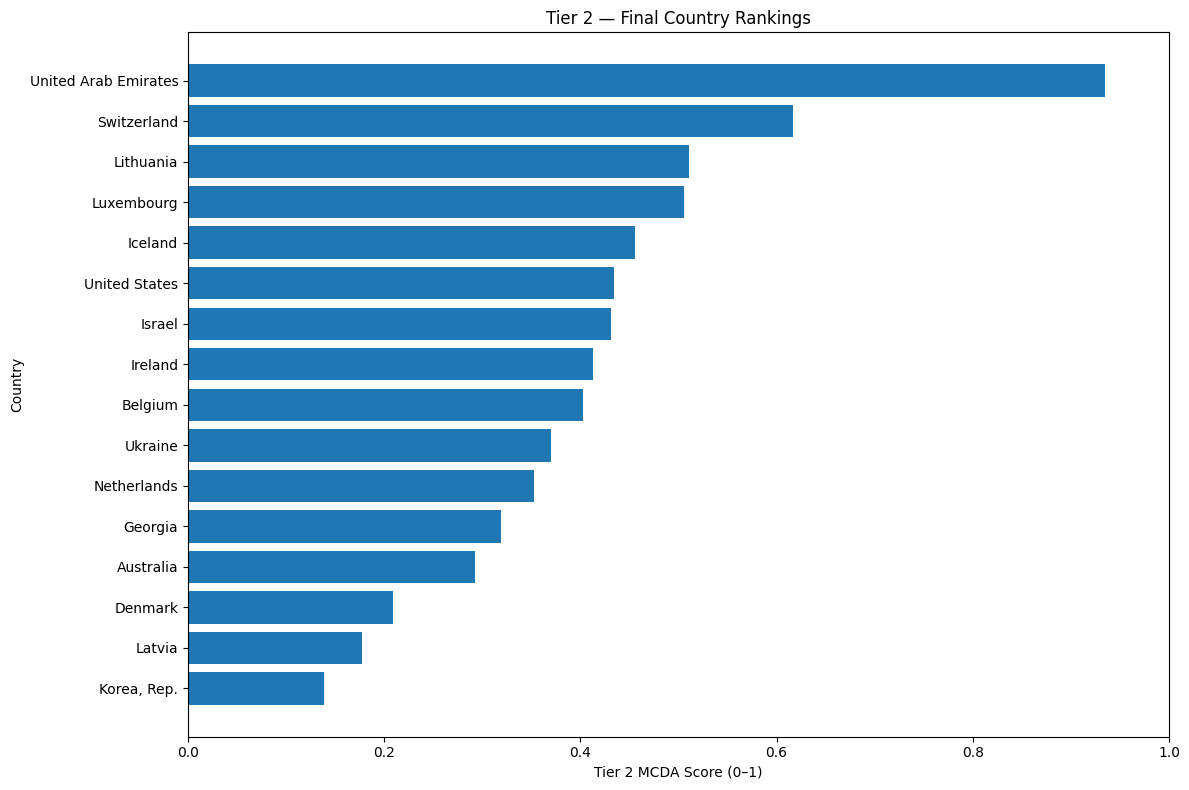

In [151]:
# ============================================================
# TIER 2 — CELL 2: COUNTRY MATCHING, CLEANING, MCDA RANKING
# ============================================================

# ------------------------------------------------------------
# 1. THE 20 LOCATIONS TO RANK
# ------------------------------------------------------------

TARGET_COUNTRIES = [
    "United Arab Emirates",
    "Russian Federation",
    "Switzerland",
    "Luxembourg",
    "Lithuania",
    "United Kingdom",
    "Ireland",
    "Iceland",
    "Israel",
    "Belgium",
    "United States",
    "Ukraine",
    "Australia",
    "Korea, Rep.",
    "Georgia",
    "Netherlands",
    "Kazakhstan",
    "Denmark",
    "Estonia",
    "Latvia"
]

# ------------------------------------------------------------
# 2. COUNTRY NAME STANDARDIZATION
# ------------------------------------------------------------

COUNTRY_ALIASES = {
    "russia": "russian federation",
    "united states of america": "united states",
    "usa": "united states",
    "uk": "united kingdom",
    "korea, rep.": "south korea",
    "republic of korea": "south korea",
    "korea, republic of": "south korea",
    "south korea": "south korea",
    "uae": "united arab emirates",
    "iran, islamic rep.": "iran",
    "the netherlands": "netherlands",
    "israel": "israel",
    "turkiye": "turkey"
}

def normalize_country(value):

    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    value = re.sub(r"\s+", " ", value)
    value = value.replace("_", " ")

    return COUNTRY_ALIASES.get(value, value)


TARGET_NORMALIZED = {
    normalize_country(country): country
    for country in TARGET_COUNTRIES
}

# ------------------------------------------------------------
# 3. INDICATOR CONFIGURATION
# ------------------------------------------------------------
#
# IMPORTANT:
# Fill country_col and value_col using the exact column names
# printed in CELL 1.
#
# year_col is optional. If supplied, the code uses the latest
# available year for each country.
#
# aggregation:
#   "mean" = average observations for that country
#   "latest" = latest year, if year_col is provided
#
# Direction:
#   "benefit" = higher is better
#   "cost"    = lower is better
#
# Do not use both homicide files as separate criteria.
# They measure the same general indicator and would double-count it.
# This configuration uses homicide_1 only.

COLUMN_MAP = {

    "homicide_1": {
        "country_col": None,
        "value_col": None,
        "year_col": None,
        "criterion": "homicide_rate",
        "category": "crime",
        "direction": "cost",
        "aggregation": "latest"
    },

    "aqi": {
        "country_col": None,
        "value_col": None,
        "year_col": None,
        "criterion": "air_quality_index",
        "category": "environment",
        "direction": "cost",
        "aggregation": "mean"
    },

    "public_space": {
        "country_col": None,
        "value_col": None,
        "year_col": None,
        "criterion": "public_space_access",
        "category": "environment",
        "direction": "benefit",
        "aggregation": "latest"
    },

    "economic_crime": {
        "country_col": None,
        "value_col": None,
        "year_col": None,
        "criterion": "economic_crime_rate",
        "category": "crime",
        "direction": "cost",
        "aggregation": "latest"
    },

    "violent_crime": {
        "country_col": None,
        "value_col": None,
        "year_col": None,
        "criterion": "violent_crime_rate",
        "category": "crime",
        "direction": "cost",
        "aggregation": "latest"
    },

    "transport": {
        "country_col": None,
        "value_col": None,
        "year_col": None,
        "criterion": "public_transport_access",
        "category": "transportation",
        "direction": "benefit",
        "aggregation": "latest"
    },

    "human_capital": {
        "country_col": None,
        "value_col": None,
        "year_col": None,
        "criterion": "human_capital_index",
        "category": "education",
        "direction": "benefit",
        "aggregation": "latest"
    },

    "pm25": {
        "country_col": None,
        "value_col": None,
        "year_col": None,
        "criterion": "pm25_exposure",
        "category": "environment",
        "direction": "cost",
        "aggregation": "latest"
    },

    "higher_education": {
        "country_col": None,
        "value_col": None,
        "year_col": None,
        "criterion": "higher_education_rate",
        "category": "education",
        "direction": "benefit",
        "aggregation": "latest"
    }
}

# ------------------------------------------------------------
# 4. AUTOMATICALLY IDENTIFY LIKELY COUNTRY AND VALUE COLUMNS
# ------------------------------------------------------------

COUNTRY_COLUMN_HINTS = [
    "country", "country_name", "country name",
    "geoarea", "geo_area", "location",
    "economy", "nation", "area"
]

YEAR_COLUMN_HINTS = [
    "year", "time", "time_period", "period"
]

def find_country_column(df):

    for col in df.columns:

        name = str(col).lower().strip()

        if any(hint in name for hint in COUNTRY_COLUMN_HINTS):
            return col

    return None


def find_year_column(df):

    for col in df.columns:

        name = str(col).lower().strip()

        if any(hint in name for hint in YEAR_COLUMN_HINTS):
            return col

    return None


def find_numeric_column(df, excluded_columns):

    candidates = []

    for col in df.columns:

        if col in excluded_columns:
            continue

        numeric = pd.to_numeric(df[col], errors="coerce")

        if numeric.notna().sum() > 0:
            candidates.append((col, numeric.notna().sum()))

    if not candidates:
        return None

    candidates.sort(key=lambda x: x[1], reverse=True)

    return candidates[0][0]


# Fill missing mappings with automatic guesses.
# Review these guesses carefully before calculating rankings.

for key, config in COLUMN_MAP.items():

    if key not in TIER2_RAW:
        continue

    df = TIER2_RAW[key]

    if config["country_col"] is None:
        config["country_col"] = find_country_column(df)

    if config["year_col"] is None:
        config["year_col"] = find_year_column(df)

    if config["value_col"] is None:

        excluded = [
            config["country_col"],
            config["year_col"]
        ]

        excluded = [x for x in excluded if x is not None]

        config["value_col"] = find_numeric_column(df, excluded)

    print(
        key,
        "| Country:", config["country_col"],
        "| Value:", config["value_col"],
        "| Year:", config["year_col"]
    )

# ------------------------------------------------------------
# 5. PREPARE AND AGGREGATE EACH DATASET
# ------------------------------------------------------------

indicator_tables = []

for key, config in COLUMN_MAP.items():

    if key not in TIER2_RAW:
        continue

    df = TIER2_RAW[key].copy()

    country_col = config["country_col"]
    value_col = config["value_col"]
    year_col = config["year_col"]

    if country_col not in df.columns or value_col not in df.columns:
        print(f"SKIPPED {key}: invalid or missing column mapping.")
        continue

    # Keep only relevant columns.
    selected_columns = [country_col, value_col]

    if year_col is not None and year_col in df.columns:
        selected_columns.append(year_col)

    temp = df[selected_columns].copy()

    temp["country_normalized"] = temp[country_col].apply(
        normalize_country
    )

    temp["value"] = pd.to_numeric(
        temp[value_col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

    temp = temp.dropna(subset=["country_normalized", "value"])

    # Match the 20 selected countries.
    temp = temp[
        temp["country_normalized"].isin(TARGET_NORMALIZED.keys())
    ].copy()

    # Use the latest available observation when a year is available.
    if (
        config["aggregation"] == "latest"
        and year_col is not None
        and year_col in temp.columns
    ):

        temp["_year_numeric"] = pd.to_numeric(
            temp[year_col], errors="coerce"
        )

        temp = temp.sort_values("_year_numeric")

        temp = temp.groupby(
            "country_normalized",
            as_index=False
        ).tail(1)

    else:

        # For repeated observations, average them by country.
        temp = (
            temp.groupby("country_normalized", as_index=False)["value"]
            .mean()
        )

    temp["country"] = temp["country_normalized"].map(
        TARGET_NORMALIZED
    )

    temp = temp[["country", "value"]].rename(
        columns={"value": config["criterion"]}
    )

    indicator_tables.append(temp)

    print(
        f"{config['criterion']}: "
        f"{len(temp)} of {len(TARGET_COUNTRIES)} countries matched"
    )

# ------------------------------------------------------------
# 6. COMBINE ALL INDICATORS
# ------------------------------------------------------------

if not indicator_tables:
    raise ValueError(
        "No datasets were successfully mapped. "
        "Check the column names in COLUMN_MAP."
    )

tier2_data = pd.DataFrame({
    "country": TARGET_COUNTRIES
})

for table in indicator_tables:

    tier2_data = tier2_data.merge(
        table,
        on="country",
        how="left"
    )

print("\nCombined Tier 2 dataset:")
display(tier2_data)

# ------------------------------------------------------------
# 7. REMOVE DUPLICATE INDICATORS
# ------------------------------------------------------------

# Homicide_2 is intentionally excluded because homicide_1
# already represents the homicide criterion.
#
# If homicide_1 has poor coverage and homicide_2 is better,
# change the source in COLUMN_MAP rather than counting both.

# ------------------------------------------------------------
# 8. DEFINE CATEGORY AND CRITERION STRUCTURE
# ------------------------------------------------------------

CRITERIA = {}

for key, config in COLUMN_MAP.items():

    criterion = config["criterion"]

    if criterion not in tier2_data.columns:
        continue

    if tier2_data[criterion].notna().sum() == 0:
        continue

    category = config["category"]

    if category not in CRITERIA:
        CRITERIA[category] = {}

    CRITERIA[category][criterion] = {
        "direction": config["direction"]
    }

print("\nActive criteria:")
for category, criteria in CRITERIA.items():
    print(category, list(criteria.keys()))

# ------------------------------------------------------------
# 9. MIN-MAX NORMALIZATION
# ------------------------------------------------------------

def minmax_normalize(series, direction):

    values = pd.to_numeric(series, errors="coerce")

    minimum = values.min()
    maximum = values.max()

    # No variation: criterion cannot distinguish locations.
    if pd.isna(minimum) or pd.isna(maximum) or maximum == minimum:
        return pd.Series(np.nan, index=series.index)

    normalized = (values - minimum) / (maximum - minimum)

    if direction == "cost":
        normalized = 1 - normalized

    return normalized


normalized_data = pd.DataFrame(index=tier2_data.index)

for category, criteria in CRITERIA.items():

    for criterion, settings in criteria.items():

        normalized_data[criterion] = minmax_normalize(
            tier2_data[criterion],
            settings["direction"]
        )

# ------------------------------------------------------------
# 10. ENTROPY WEIGHTING FUNCTION
# ------------------------------------------------------------

def calculate_entropy_weights(normalized_df):

    weights = {}

    valid_columns = [
        col for col in normalized_df.columns
        if normalized_df[col].notna().sum() > 1
        and normalized_df[col].nunique(dropna=True) > 1
    ]

    if not valid_columns:
        return pd.Series(dtype=float)

    df = normalized_df[valid_columns].copy()

    n = len(df)

    if n <= 1:
        return pd.Series(dtype=float)

    epsilon = 1e-12

    for col in df.columns:

        values = df[col].copy()

        # Calculate proportions using available observations only.
        values = values.clip(lower=0)

        total = values.sum()

        if total <= 0:
            weights[col] = 0
            continue

        p = values / total

        p = p.replace(0, epsilon)

        entropy = -np.sum(p * np.log(p)) / np.log(n)

        divergence = max(0, 1 - entropy)

        weights[col] = divergence

    weights = pd.Series(weights, dtype=float)

    if weights.sum() == 0:
        return pd.Series(
            1 / len(weights),
            index=weights.index
        )

    return weights / weights.sum()


# ------------------------------------------------------------
# 11. HIERARCHICAL CATEGORY AND CRITERION WEIGHTS
# ------------------------------------------------------------

category_weights = {}
within_category_weights = {}

for category, criteria in CRITERIA.items():

    columns = [
        criterion
        for criterion in criteria
        if criterion in normalized_data.columns
    ]

    if not columns:
        continue

    within_weights = calculate_entropy_weights(
        normalized_data[columns]
    )

    if within_weights.empty:
        continue

    within_category_weights[category] = within_weights

    # Category discrimination is based on its average
    # normalized performance across available criteria.
    category_matrix = normalized_data[columns]

    category_composite = category_matrix.mean(axis=1)

    category_weights[category] = category_composite


category_weights = pd.Series(category_weights, dtype=object)

# Calculate entropy weights between categories.
category_matrix = pd.DataFrame(category_weights.to_dict())

category_entropy_weights = calculate_entropy_weights(
    category_matrix
)

# ------------------------------------------------------------
# 12. FINAL GLOBAL CRITERION WEIGHTS
# ------------------------------------------------------------

global_weights = {}

for category, within_weights in within_category_weights.items():

    if category not in category_entropy_weights.index:
        continue

    category_weight = category_entropy_weights[category]

    for criterion, within_weight in within_weights.items():

        global_weights[criterion] = (
            category_weight * within_weight
        )

global_weights = pd.Series(global_weights, dtype=float)

if global_weights.empty or global_weights.sum() == 0:
    raise ValueError(
        "Could not calculate meaningful entropy weights. "
        "Check the data variation and mappings."
    )

global_weights = global_weights / global_weights.sum()

print("\nCATEGORY WEIGHTS:")
display(category_entropy_weights.sort_values(ascending=False))

print("\nGLOBAL CRITERION WEIGHTS:")
display(global_weights.sort_values(ascending=False))

# ------------------------------------------------------------
# 13. CALCULATE SCORES WITH MISSING-DATA RENORMALIZATION
# ------------------------------------------------------------

scores = []
coverage_values = []

for index, row in normalized_data.iterrows():

    available = row.notna()

    available_weights = global_weights[
        global_weights.index.isin(row.index[available])
    ]

    denominator = available_weights.sum()

    if denominator <= 0:

        scores.append(np.nan)
        coverage_values.append(0)

        continue

    weighted_score = sum(
        row[criterion] * global_weights[criterion]
        for criterion in available_weights.index
        if pd.notna(row[criterion])
    )

    score = weighted_score / denominator

    coverage = denominator / global_weights.sum()

    scores.append(score)
    coverage_values.append(coverage)


tier2_data["tier2_score"] = scores
tier2_data["data_coverage"] = coverage_values

# ------------------------------------------------------------
# 14. RANK LOCATIONS
# ------------------------------------------------------------

MIN_DATA_COVERAGE = 0.40

tier2_data["rank"] = (
    tier2_data["tier2_score"]
    .rank(ascending=False, method="min")
)

tier2_rankings = (
    tier2_data[
        tier2_data["data_coverage"] >= MIN_DATA_COVERAGE
    ]
    .dropna(subset=["tier2_score"])
    .sort_values("tier2_score", ascending=False)
    .reset_index(drop=True)
)

tier2_rankings["rank"] = np.arange(
    1, len(tier2_rankings) + 1
)

print("\n" + "=" * 80)
print("FINAL TIER 2 COUNTRY RANKINGS")
print("=" * 80)

display(
    tier2_rankings[
        ["rank", "country", "tier2_score", "data_coverage"]
    ].style.format({
        "tier2_score": "{:.4f}",
        "data_coverage": "{:.1%}"
    })
)

# ------------------------------------------------------------
# 15. EXPORT RESULTS
# ------------------------------------------------------------

tier2_rankings.to_csv(
    "HiMCM_Tier2_Final_Rankings.csv",
    index=False
)

tier2_data.to_csv(
    "HiMCM_Tier2_All_Country_Scores.csv",
    index=False
)

global_weights.rename(
    "global_weight"
).to_csv(
    "HiMCM_Tier2_Criterion_Weights.csv"
)

category_entropy_weights.rename(
    "category_weight"
).to_csv(
    "HiMCM_Tier2_Category_Weights.csv"
)

print("\nExported:")
print("1. HiMCM_Tier2_Final_Rankings.csv")
print("2. HiMCM_Tier2_All_Country_Scores.csv")
print("3. HiMCM_Tier2_Criterion_Weights.csv")
print("4. HiMCM_Tier2_Category_Weights.csv")

# ------------------------------------------------------------
# 16. VISUALIZE FINAL RANKINGS
# ------------------------------------------------------------

if not tier2_rankings.empty:

    plt.figure(figsize=(12, 8))

    plt.barh(
        tier2_rankings["country"][::-1],
        tier2_rankings["tier2_score"][::-1]
    )

    plt.xlabel("Tier 2 MCDA Score (0–1)")
    plt.ylabel("Country")
    plt.title("Tier 2 — Final Country Rankings")

    plt.xlim(0, 1)
    plt.tight_layout()
    plt.show()

In [152]:
# ============================================================
# TIER 2 — CELL 3: MONTE CARLO SENSITIVITY ANALYSIS
# ============================================================

MONTE_CARLO_DRAWS = 1000
DIRICHLET_CONCENTRATION = 80
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

# Use only criteria with valid calculated weights.
active_weights = global_weights.dropna()

active_weights = active_weights[
    active_weights > 0
]

active_weights = active_weights / active_weights.sum()

simulation_data = normalized_data[
    active_weights.index
].copy()

draw_results = []

for draw in range(MONTE_CARLO_DRAWS):

    # Perturb weights around their baseline values.
    alpha = np.maximum(
        active_weights.values * DIRICHLET_CONCENTRATION,
        0.02
    )

    sampled_weights = rng.dirichlet(alpha)

    sampled_weights = pd.Series(
        sampled_weights,
        index=active_weights.index
    )

    # Score each country with available observations only.
    for index, row in simulation_data.iterrows():

        available = row.notna()

        available_weights = sampled_weights[
            available.reindex(sampled_weights.index).fillna(False).values
        ]

        if available_weights.sum() <= 0:
            score = np.nan

        else:

            valid_criteria = available_weights.index

            score = sum(
                row[col] * available_weights[col]
                for col in valid_criteria
            ) / available_weights.sum()

        draw_results.append({
            "country": tier2_data.loc[index, "country"],
            "draw": draw,
            "score": score
        })

simulation = pd.DataFrame(draw_results)

simulation["rank"] = simulation.groupby(
    "draw"
)["score"].rank(
    ascending=False,
    method="min"
)

# ------------------------------------------------------------
# SUMMARIZE ROBUSTNESS
# ------------------------------------------------------------

robustness = (
    simulation.groupby("country")
    .agg(
        mean_score=("score", "mean"),
        score_std=("score", "std"),
        first_place_frequency=(
            "rank",
            lambda x: (x == 1).mean()
        ),
        top_5_frequency=(
            "rank",
            lambda x: (x <= 5).mean()
        ),
        average_rank=("rank", "mean")
    )
    .reset_index()
    .sort_values(
        ["first_place_frequency", "mean_score"],
        ascending=False
    )
)

print("TIER 2 MONTE CARLO ROBUSTNESS")
display(
    robustness.style.format({
        "mean_score": "{:.4f}",
        "score_std": "{:.4f}",
        "first_place_frequency": "{:.1%}",
        "top_5_frequency": "{:.1%}",
        "average_rank": "{:.2f}"
    })
)

robustness.to_csv(
    "HiMCM_Tier2_Sensitivity_Analysis.csv",
    index=False
)

print("Sensitivity analysis exported.")

TIER 2 MONTE CARLO ROBUSTNESS


,country,mean_score,score_std,first_place_frequency,top_5_frequency,average_rank
14,Russian Federation,0.9517,0.0000,88.8%,100.0%,1.11
17,United Arab Emirates,0.9343,0.0152,11.2%,100.0%,2.91
3,Estonia,0.9508,0.0000,0.0%,100.0%,2.12
8,Kazakhstan,0.9183,0.0000,0.0%,100.0%,3.85
15,Switzerland,0.6168,0.0156,0.0%,100.0%,5.00
11,Lithuania,0.5108,0.0239,0.0%,0.0%,6.00
12,Luxembourg,0.5055,0.0257,0.0%,0.0%,7.00
5,Iceland,0.4559,0.0287,0.0%,0.0%,8.00
19,United States,0.4342,0.0250,0.0%,0.0%,9.21
7,Israel,0.4315,0.0218,0.0%,0.0%,9.79


Sensitivity analysis exported.


In [153]:
# ============================================================
# CELL 12B: LOAD AND AUDIT ALL TIER 2 DATASETS
# ============================================================

import pandas as pd
import numpy as np
import re
import os
import warnings

# ------------------------------------------------------------
# 1. CHECK THAT CELL 12A HAS BEEN RUN
# ------------------------------------------------------------

if "REGIONAL_BOUNDARIES" not in globals():
    raise NameError("Run Cell 12A first.")

if REGIONAL_BOUNDARIES.empty:
    raise ValueError("No regional boundaries were retrieved.")

# ------------------------------------------------------------
# 2. DATASET FILENAMES
# ------------------------------------------------------------

TIER2_FILES = {
    "public_space": "SDG_11.7.1_July_2026.csv",

    "homicide_1":
        "Intentional homicides (per 100,000 people) - Sheet1 (1).csv",

    "aqi":
        "AQI and Lat Long of Countries.csv",

    "corruption":
        "data_cts_corruption_and_economic_crime (1).xlsx - data_cts_corruption_and_economi.csv",

    "violent_crime":
        "data_cts_violent_and_sexual_crime (1).xlsx - data_cts_violent_and_sexual_cri.csv",

    "public_transport":
        "SDG_11.2.1_July_2026.csv",

    "healthcare":
        "WB_HCP_TEST.csv",

    "pm25":
        "Mean_Population_Exposure_to_PM2.5_by_Country,_2015_-_2019.xls - Data.csv",

    "homicide_2":
        "Intentional homicides (per 100,000 people) - Sheet1.csv",

    "higher_education":
        "Attained higher Ed percentage.csv"
}

# ------------------------------------------------------------
# 3. LOAD FILES
# ------------------------------------------------------------

DATASETS = {}

for key, filename in TIER2_FILES.items():

    if not os.path.exists(filename):
        print("MISSING FILE:", filename)
        continue

    try:
        df = pd.read_csv(filename, encoding="utf-8-sig")

    except UnicodeDecodeError:
        df = pd.read_csv(filename, encoding="latin1")

    # Remove unnecessary spaces from column names.
    df.columns = df.columns.astype(str).str.strip()

    DATASETS[key] = df

    print(
        f"\nLoaded: {key}",
        f"\nRows: {len(df):,}",
        f"\nColumns: {len(df.columns)}"
    )

print("\nTOTAL DATASETS LOADED:", len(DATASETS))

# ------------------------------------------------------------
# 4. AUTOMATICALLY IDENTIFY POSSIBLE COLUMNS
# ------------------------------------------------------------

def normalize_text(value):

    value = str(value).lower().strip()

    value = re.sub(r"[^a-z0-9]+", " ", value)

    return re.sub(r"\s+", " ", value).strip()


GEO_KEYWORDS = [
    "region", "province", "state", "admin1",
    "subnational", "district", "location",
    "geography", "area", "city"
]

COUNTRY_KEYWORDS = [
    "country", "nation", "country name",
    "geoareaname", "economy"
]

YEAR_KEYWORDS = [
    "year", "time", "period", "date"
]

VALUE_KEYWORDS = [
    "value", "rate", "percent", "percentage",
    "index", "score", "mean", "average",
    "estimate", "observation", "total"
]


def find_candidates(columns, keywords):

    matches = []

    for col in columns:

        normalized = normalize_text(col)

        if any(keyword in normalized for keyword in keywords):
            matches.append(col)

    return matches


def inspect_dataset(key, df):

    print("\n" + "=" * 80)
    print("DATASET:", key)
    print("=" * 80)

    print("\nALL COLUMNS:")
    print(list(df.columns))

    print("\nPOSSIBLE REGION COLUMNS:")
    print(find_candidates(df.columns, GEO_KEYWORDS))

    print("\nPOSSIBLE COUNTRY COLUMNS:")
    print(find_candidates(df.columns, COUNTRY_KEYWORDS))

    print("\nPOSSIBLE YEAR COLUMNS:")
    print(find_candidates(df.columns, YEAR_KEYWORDS))

    print("\nPOSSIBLE VALUE COLUMNS:")
    print(find_candidates(df.columns, VALUE_KEYWORDS))

    print("\nNUMERIC COLUMNS:")

    print(
        df.select_dtypes(include=np.number).columns.tolist()
    )

    print("\nFIRST FIVE ROWS:")
    display(df.head())


for key, df in DATASETS.items():

    inspect_dataset(key, df)


Loaded: public_space 
Rows: 3,663 
Columns: 15

Loaded: homicide_1 
Rows: 608 
Columns: 1

Loaded: aqi 
Rows: 16,695 
Columns: 14

Loaded: corruption 
Rows: 27,081 
Columns: 13

Loaded: violent_crime 
Rows: 34,976 
Columns: 13

Loaded: public_transport 
Rows: 2,927 
Columns: 14

Loaded: healthcare 
Rows: 1,727 
Columns: 41

Loaded: pm25 
Rows: 2,686 
Columns: 8

Loaded: homicide_2 
Rows: 608 
Columns: 1

Loaded: higher_education 
Rows: 271 
Columns: 16

TOTAL DATASETS LOADED: 10

DATASET: public_space

ALL COLUMNS:
['SDG Goal', 'SDG Target', 'SDG Indicator', 'Country or Territory Code', 'Country or Territory Name', 'SDG Region', 'SDG Sub-Region', 'City Code', 'City Name', 'Average share of the built-up area of cities that is open space for public use for all (%) [a]', 'Average share of urban population with convenient access to open public spaces (%) [b]', 'Data Units', 'Data Reference Year', 'Data Source', 'FootNote']

POSSIBLE REGION COLUMNS:
['SDG Region', 'SDG Sub-Region', 'City C

,SDG Goal,SDG Target,SDG Indicator,Country or Territory Code,Country or Territory Name,SDG Region,SDG Sub-Region,City Code,City Name,Average share of the built-up area of cities that is open space for public use for all (%) [a],Average share of urban population with convenient access to open public spaces (%) [b],Data Units,Data Reference Year,Data Source,FootNote
0,11,11.7,11.7.1,4,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_KABUL,Kabul,19.2,NaN,PERCENT,2025,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...
1,11,11.7,11.7.1,4,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_CHARIKAR,Chārīkār,17.9,82.1,PERCENT,2020,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...
2,11,11.7,11.7.1,4,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_FARAH,Farāh,12.1,62.5,PERCENT,2020,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...
3,11,11.7,11.7.1,4,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_HERAT,Herat,17.2,55.6,PERCENT,2020,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...
4,11,11.7,11.7.1,4,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_JALALABAD,Jalālābād,15.7,59.0,PERCENT,2020,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...



DATASET: homicide_1

ALL COLUMNS:
['Afghanistan']

POSSIBLE REGION COLUMNS:
[]

POSSIBLE COUNTRY COLUMNS:
[]

POSSIBLE YEAR COLUMNS:
[]

POSSIBLE VALUE COLUMNS:
[]

NUMERIC COLUMNS:
[]

FIRST FIVE ROWS:


,Afghanistan
0,2021
1,4
2,Albania
3,2023
4,1



DATASET: aqi

ALL COLUMNS:
['Country', 'City', 'AQI Value', 'AQI Category', 'CO AQI Value', 'CO AQI Category', 'Ozone AQI Value', 'Ozone AQI Category', 'NO2 AQI Value', 'NO2 AQI Category', 'PM2.5 AQI Value', 'PM2.5 AQI Category', 'lat', 'lng']

POSSIBLE REGION COLUMNS:
['City']

POSSIBLE COUNTRY COLUMNS:
['Country']

POSSIBLE YEAR COLUMNS:
[]

POSSIBLE VALUE COLUMNS:
['AQI Value', 'CO AQI Value', 'Ozone AQI Value', 'NO2 AQI Value', 'PM2.5 AQI Value']

NUMERIC COLUMNS:
['AQI Value', 'CO AQI Value', 'Ozone AQI Value', 'NO2 AQI Value', 'PM2.5 AQI Value', 'lat', 'lng']

FIRST FIVE ROWS:


,Country,City,AQI Value,AQI Category,CO AQI Value,CO AQI Category,Ozone AQI Value,Ozone AQI Category,NO2 AQI Value,NO2 AQI Category,PM2.5 AQI Value,PM2.5 AQI Category,lat,lng
0,Russian Federation,Praskoveya,51,Moderate,1,Good,36,Good,0,Good,51,Moderate,44.7444,44.2031
1,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good,-5.2900,-44.4900
2,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good,-11.2958,-41.9869
3,Italy,Priolo Gargallo,66,Moderate,1,Good,39,Good,2,Good,66,Moderate,37.1667,15.1833
4,Poland,Przasnysz,34,Good,1,Good,34,Good,0,Good,20,Good,53.0167,20.8833


... (10 outputs left out)


DATASET: homicide_2

ALL COLUMNS:
['Afghanistan']

POSSIBLE REGION COLUMNS:
[]

POSSIBLE COUNTRY COLUMNS:
[]

POSSIBLE YEAR COLUMNS:
[]

POSSIBLE VALUE COLUMNS:
[]

NUMERIC COLUMNS:
[]

FIRST FIVE ROWS:


,Afghanistan
0,2021
1,4
2,Albania
3,2023
4,1



DATASET: higher_education

ALL COLUMNS:
['Series Name', 'Series Code', 'Country Name', 'Country Code', '1990 [YR1990]', '2000 [YR2000]', '2016 [YR2016]', '2017 [YR2017]', '2018 [YR2018]', '2019 [YR2019]', '2020 [YR2020]', '2021 [YR2021]', '2022 [YR2022]', '2023 [YR2023]', '2024 [YR2024]', '2025 [YR2025]']

POSSIBLE REGION COLUMNS:
[]

POSSIBLE COUNTRY COLUMNS:
['Country Name', 'Country Code']

POSSIBLE YEAR COLUMNS:
[]

POSSIBLE VALUE COLUMNS:
[]

NUMERIC COLUMNS:
[]

FIRST FIVE ROWS:


,Series Name,Series Code,Country Name,Country Code,1990 [YR1990],2000 [YR2000],2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
0,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,Afghanistan,AFG,..,..,..,5.26141700354864,..,..,3.71811698299556,3.06798005104065,3.98425006866455,..,..,..
1,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,Albania,ALB,..,..,14.3157503195291,16.1501998901367,16.4676840857403,17.3219430335689,17.804132917267,18.2029345963076,19.8346436163563,17.5054893493652,..,..
2,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,Algeria,DZA,..,..,..,..,..,11.4359302520752,..,..,..,..,..,..
3,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,American Samoa,ASM,..,..,..,..,..,..,..,..,..,..,..,..
4,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,Andorra,AND,..,..,21.0465507507324,..,..,..,..,..,25.0374794006348,..,..,..


In [154]:

# ============================================================
# CELL 12C: DIAGNOSE AND MATCH TIER 2 REGIONAL DATASETS
# ============================================================

import pandas as pd
import numpy as np
import re

# ------------------------------------------------------------
# 1. VERIFY INPUTS
# ------------------------------------------------------------

if "DATASETS" not in globals():
    raise NameError("Run Cell 12B first.")

if "REGIONAL_BOUNDARIES" not in globals():
    raise NameError("Run Cell 12A first.")

# ------------------------------------------------------------
# 2. NORMALIZE TEXT
# ------------------------------------------------------------

def normalize_text(value):

    if pd.isna(value):
        return ""

    value = str(value).strip().lower()

    value = re.sub(r"[^a-z0-9]+", " ", value)

    return re.sub(r"\s+", " ", value).strip()


# ------------------------------------------------------------
# 3. CREATE OFFICIAL ADM1 REFERENCE
# ------------------------------------------------------------

REGION_REFERENCE = REGIONAL_BOUNDARIES.copy()

REGION_REFERENCE["region_key"] = (
    REGION_REFERENCE["region"].apply(normalize_text)
)

REGION_REFERENCE["country_key"] = (
    REGION_REFERENCE["country"].apply(normalize_text)
)

REGION_REFERENCE["match_key"] = (
    REGION_REFERENCE["country_key"]
    + "||"
    + REGION_REFERENCE["region_key"]
)

VALID_REGION_KEYS = set(
    REGION_REFERENCE["match_key"]
)

VALID_REGION_NAMES = set(
    REGION_REFERENCE["region_key"]
)

# Only accept region-only matches if the name occurs
# in exactly one country.

REGION_COUNTRY_COUNTS = (
    REGION_REFERENCE.groupby("region_key")["country_key"]
    .nunique()
)

UNIQUE_REGION_NAMES = set(
    REGION_COUNTRY_COUNTS[
        REGION_COUNTRY_COUNTS == 1
    ].index
)

# ------------------------------------------------------------
# 4. FIND COUNTRY CODES
# ------------------------------------------------------------

COUNTRY_CODE_LOOKUP = {}

for _, row in REGION_REFERENCE.iterrows():

    COUNTRY_CODE_LOOKUP[
        normalize_text(row["country"])
    ] = normalize_text(row["country"])

    COUNTRY_CODE_LOOKUP[
        normalize_text(row["iso3"])
    ] = normalize_text(row["country"])

# Add common ISO2 codes.
ISO2_CODES = {
    "CAN": "CA",
    "AUS": "AU",
    "ISL": "IS",
    "NZL": "NZ",
    "SGP": "SG",
    "USA": "US",
    "GBR": "GB",
    "NOR": "NO",
    "CHE": "CH",
    "DEU": "DE",
    "BEL": "BE",
    "FIN": "FI",
    "MCO": "MC",
    "CUB": "CU",
    "NLD": "NL",
    "LUX": "LU",
    "KOR": "KR"
}

for iso3, iso2 in ISO2_CODES.items():

    country = REGION_REFERENCE.loc[
        REGION_REFERENCE["iso3"] == iso3,
        "country"
    ]

    if not country.empty:

        COUNTRY_CODE_LOOKUP[
            normalize_text(iso2)
        ] = normalize_text(country.iloc[0])


# ------------------------------------------------------------
# 5. INSPECT EVERY DATASET
# ------------------------------------------------------------

REGIONAL_DATASET_AUDIT = []

REGIONAL_COLUMN_CANDIDATES = {}

for dataset_name, original_df in DATASETS.items():

    df = original_df.copy()

    print("\n" + "=" * 90)
    print("DATASET:", dataset_name)
    print("=" * 90)

    print("\nCOLUMNS:")
    print(df.columns.tolist())

    # --------------------------------------------------------
    # Search EVERY column for ADM1 region-name matches.
    # --------------------------------------------------------

    region_candidates = []

    for column in df.columns:

        values = (
            df[column]
            .dropna()
            .astype(str)
            .apply(normalize_text)
        )

        matched_values = values[
            values.isin(VALID_REGION_NAMES)
        ]

        overlap = matched_values.nunique()

        if overlap > 0:

            region_candidates.append({
                "column": column,
                "matched_regions": overlap,
                "sample_matches": matched_values.unique()[:8].tolist()
            })

    region_candidates = sorted(
        region_candidates,
        key=lambda x: x["matched_regions"],
        reverse=True
    )

    print("\nREGION COLUMN CANDIDATES:")

    if region_candidates:

        display(pd.DataFrame(region_candidates))

    else:

        print("No exact ADM1 region-name matches found.")

    # --------------------------------------------------------
    # Identify numeric or numeric-looking columns.
    # --------------------------------------------------------

    value_candidates = []

    for column in df.columns:

        numeric_values = pd.to_numeric(
            df[column],
            errors="coerce"
        )

        valid_count = numeric_values.notna().sum()

        if valid_count > 0:

            value_candidates.append({
                "column": column,
                "valid_numeric_values": int(valid_count),
                "unique_numeric_values": int(
                    numeric_values.nunique()
                ),
                "sample_values": numeric_values.dropna().head(5).tolist()
            })

    value_candidates = sorted(
        value_candidates,
        key=lambda x: x["valid_numeric_values"],
        reverse=True
    )

    print("\nNUMERIC VALUE COLUMN CANDIDATES:")

    if value_candidates:

        display(pd.DataFrame(value_candidates))

    else:

        print("No numeric columns found.")

    # --------------------------------------------------------
    # Print country column candidates.
    # --------------------------------------------------------

    print("\nPOSSIBLE COUNTRY COLUMNS:")

    country_candidates = []

    for column in df.columns:

        normalized_column = normalize_text(column)

        if any(
            word in normalized_column
            for word in [
                "country", "economy",
                "territory", "geoarea",
                "location"
            ]
        ):

            country_candidates.append(column)

    print(country_candidates)

    # --------------------------------------------------------
    # Store audit results.
    # --------------------------------------------------------

    best_region = (
        region_candidates[0]["column"]
        if region_candidates else None
    )

    REGIONAL_COLUMN_CANDIDATES[dataset_name] = {
        "region_candidates": region_candidates,
        "value_candidates": value_candidates,
        "country_candidates": country_candidates
    }

    REGIONAL_DATASET_AUDIT.append({
        "dataset": dataset_name,
        "best_region_column": best_region,
        "regions_matched": (
            region_candidates[0]["matched_regions"]
            if region_candidates else 0
        ),
        "numeric_columns_found": len(value_candidates),
        "regional_match_found": bool(region_candidates)
    })

    print("\nFIRST FIVE ROWS:")
    display(df.head())


# ------------------------------------------------------------
# 6. FINAL DIAGNOSTIC SUMMARY
# ------------------------------------------------------------

REGIONAL_DATASET_AUDIT = pd.DataFrame(
    REGIONAL_DATASET_AUDIT
)

print("\n" + "=" * 90)
print("FINAL TIER 2 DATASET DIAGNOSTIC")
print("=" * 90)

display(
    REGIONAL_DATASET_AUDIT.sort_values(
        "regions_matched",
        ascending=False
    )
)

print(
    "\nTOTAL DATASETS:",
    len(DATASETS)
)

print(
    "DATASETS WITH EXACT ADM1 MATCHES:",
    REGIONAL_DATASET_AUDIT[
        "regional_match_found"
    ].sum()
)

print(
    "\nIMPORTANT: This cell only identifies potential matches."
    "\nIt does not calculate rankings or assign national"
    "\nobservations to individual states and provinces."
)



DATASET: public_space

COLUMNS:
['SDG Goal', 'SDG Target', 'SDG Indicator', 'Country or Territory Code', 'Country or Territory Name', 'SDG Region', 'SDG Sub-Region', 'City Code', 'City Name', 'Average share of the built-up area of cities that is open space for public use for all (%) [a]', 'Average share of urban population with convenient access to open public spaces (%) [b]', 'Data Units', 'Data Reference Year', 'Data Source', 'FootNote']

REGION COLUMN CANDIDATES:


,column,matched_regions,sample_matches
0,City Name,19,"[montana, victoria, holgu n, cienfuegos, guant..."
1,Country or Territory Name,4,"[georgia, guam, monaco, puerto rico]"



NUMERIC VALUE COLUMN CANDIDATES:


,column,valid_numeric_values,unique_numeric_values,sample_values
0,SDG Goal,3663,1,"[11, 11, 11, 11, 11]"
1,SDG Target,3663,1,"[11.7, 11.7, 11.7, 11.7, 11.7]"
2,Country or Territory Code,3663,215,"[4, 4, 4, 4, 4]"
3,Data Reference Year,3663,12,"[2025, 2020, 2020, 2020, 2020]"
4,Average share of the built-up area of cities t...,3216,461,"[19.2, 17.9, 12.1, 17.2, 15.7]"
5,Average share of urban population with conveni...,1982,841,"[82.1, 62.5, 55.6, 59.0, 13.0]"



POSSIBLE COUNTRY COLUMNS:
['Country or Territory Code', 'Country or Territory Name']

FIRST FIVE ROWS:


,SDG Goal,SDG Target,SDG Indicator,Country or Territory Code,Country or Territory Name,SDG Region,SDG Sub-Region,City Code,City Name,Average share of the built-up area of cities that is open space for public use for all (%) [a],Average share of urban population with convenient access to open public spaces (%) [b],Data Units,Data Reference Year,Data Source,FootNote
0,11,11.7,11.7.1,4,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_KABUL,Kabul,19.2,NaN,PERCENT,2025,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...
1,11,11.7,11.7.1,4,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_CHARIKAR,Chārīkār,17.9,82.1,PERCENT,2020,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...
2,11,11.7,11.7.1,4,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_FARAH,Farāh,12.1,62.5,PERCENT,2020,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...
3,11,11.7,11.7.1,4,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_HERAT,Herat,17.2,55.6,PERCENT,2020,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...
4,11,11.7,11.7.1,4,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_JALALABAD,Jalālābād,15.7,59.0,PERCENT,2020,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...


... (53 outputs left out)

,Series Name,Series Code,Country Name,Country Code,1990 [YR1990],2000 [YR2000],2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
0,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,Afghanistan,AFG,..,..,..,5.26141700354864,..,..,3.71811698299556,3.06798005104065,3.98425006866455,..,..,..
1,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,Albania,ALB,..,..,14.3157503195291,16.1501998901367,16.4676840857403,17.3219430335689,17.804132917267,18.2029345963076,19.8346436163563,17.5054893493652,..,..
2,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,Algeria,DZA,..,..,..,..,..,11.4359302520752,..,..,..,..,..,..
3,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,American Samoa,ASM,..,..,..,..,..,..,..,..,..,..,..,..
4,"Educational attainment, at least Bachelor's or...",SE.TER.CUAT.BA.ZS,Andorra,AND,..,..,21.0465507507324,..,..,..,..,..,25.0374794006348,..,..,..



FINAL TIER 2 DATASET DIAGNOSTIC


,dataset,best_region_column,regions_matched,numeric_columns_found,regional_match_found
7,pm25,Unnamed: 1,119,5,True
2,aqi,City,33,7,True
5,public_transport,City Name,22,5,True
0,public_space,City Name,19,6,True
1,homicide_1,Afghanistan,4,1,True
8,homicide_2,Afghanistan,4,1,True
9,higher_education,Country Name,4,11,True
3,corruption,unodc-stats@un.org,3,2,True
4,violent_crime,unodc-stats@un.org,3,2,True
6,healthcare,REF_AREA_LABEL,1,5,True



TOTAL DATASETS: 10
DATASETS WITH EXACT ADM1 MATCHES: 10

IMPORTANT: This cell only identifies potential matches.
It does not calculate rankings or assign national
observations to individual states and provinces.


In [155]:

# FIX 1: Allow large GeoJSON features (especially Canada)

import os

os.environ["OGR_GEOJSON_MAX_OBJ_SIZE"] = "0"

try:
    from osgeo import gdal
    gdal.SetConfigOption("OGR_GEOJSON_MAX_OBJ_SIZE", "0")
except ImportError:
    pass

print("GeoJSON size limit configured.")


GeoJSON size limit configured.


In [156]:

# ============================================================
# CELL 12D: EXTRACT AND VALIDATE TRUE REGIONAL PM2.5 DATA
# ============================================================

import pandas as pd
import numpy as np
import re

# ------------------------------------------------------------
# 1. VERIFY INPUTS
# ------------------------------------------------------------

if "DATASETS" not in globals():
    raise NameError("Run Cell 12B first.")

if "REGIONAL_BOUNDARIES" not in globals():
    raise NameError("Run Cell 12A first.")

if "pm25" not in DATASETS:
    raise KeyError("The pm25 dataset was not found in DATASETS.")

# ------------------------------------------------------------
# 2. NORMALIZATION
# ------------------------------------------------------------

def norm_region(value):
    if pd.isna(value):
        return ""
    value = str(value).strip().lower()
    value = re.sub(r"[^a-z0-9]+", " ", value)
    return re.sub(r"\s+", " ", value).strip()

# ------------------------------------------------------------
# 3. RECONSTRUCT THE PM2.5 HEADERS
# ------------------------------------------------------------

raw = DATASETS["pm25"].copy()

header_row = None

for i in range(len(raw)):
    values = [norm_region(x) for x in raw.iloc[i].tolist()]

    if "country" in values and "subnational regions" in values:
        header_row = i
        break

if header_row is None:
    raise ValueError(
        "Could not find the actual Country/Subnational Regions header."
    )

new_headers = [
    str(x).strip() if not pd.isna(x) else ""
    for x in raw.iloc[header_row].tolist()
]

pm = raw.iloc[header_row + 1:].copy()
pm.columns = new_headers
pm = pm.reset_index(drop=True)

# Remove completely empty columns.
pm = pm.loc[:, [
    str(c).strip() != "" and not str(c).startswith("Unnamed")
    or pm[c].notna().any()
    for c in pm.columns
]]

# ------------------------------------------------------------
# 4. IDENTIFY REQUIRED COLUMNS
# ------------------------------------------------------------

column_lookup = {
    norm_region(c): c for c in pm.columns
}

required = ["country", "subnational regions"]

missing = [
    c for c in required
    if c not in column_lookup
]

if missing:
    raise ValueError(
        f"Missing required PM2.5 columns: {missing}"
    )

country_col = column_lookup["country"]
region_col = column_lookup["subnational regions"]

year_cols = [
    c for c in pm.columns
    if re.search(r"201[5-9]", str(c))
]

if not year_cols:
    raise ValueError(
        "No 2015–2019 observation columns were identified."
    )

print("PM2.5 year columns:", year_cols)

# ------------------------------------------------------------
# 5. KEEP ONLY SUBNATIONAL OBSERVATIONS
# ------------------------------------------------------------

pm[country_col] = pm[country_col].astype(str).str.strip()
pm[region_col] = pm[region_col].astype(str).str.strip()

pm = pm[
    pm[country_col].notna()
    & pm[region_col].notna()
    & (pm[country_col].str.lower() != "nan")
    & (pm[region_col].str.lower() != "nan")
    & (pm[region_col] != "")
].copy()

for col in year_cols:
    pm[col] = pd.to_numeric(pm[col], errors="coerce")

pm["pm25_mean_2015_2019"] = pm[year_cols].mean(axis=1)
pm["pm25_year_count"] = pm[year_cols].notna().sum(axis=1)

pm = pm[
    pm["pm25_mean_2015_2019"].notna()
].copy()

pm["country_key"] = pm[country_col].apply(norm_region)
pm["region_key"] = pm[region_col].apply(norm_region)

# ------------------------------------------------------------
# 6. CREATE COUNTRY + REGION MATCH KEYS
# ------------------------------------------------------------

boundaries = REGIONAL_BOUNDARIES.copy()

boundaries["country_key"] = (
    boundaries["country"].apply(norm_region)
)

boundaries["region_key"] = (
    boundaries["region"].apply(norm_region)
)

boundaries["match_key"] = (
    boundaries["country_key"]
    + "||"
    + boundaries["region_key"]
)

pm["match_key"] = (
    pm["country_key"]
    + "||"
    + pm["region_key"]
)

# ------------------------------------------------------------
# 7. MATCH ONLY EXACT COUNTRY-REGION PAIRS
# ------------------------------------------------------------

valid_keys = set(boundaries["match_key"])

pm["valid_adm1_match"] = pm["match_key"].isin(valid_keys)

matched = pm[pm["valid_adm1_match"]].copy()
unmatched = pm[~pm["valid_adm1_match"]].copy()

# ------------------------------------------------------------
# 8. AGGREGATE DUPLICATE REGIONAL RECORDS
# ------------------------------------------------------------

PM25_REGIONAL = (
    matched.groupby("match_key", as_index=False)
    .agg(
        pm25_mean_2015_2019=(
            "pm25_mean_2015_2019", "mean"
        ),
        pm25_year_count=(
            "pm25_year_count", "max"
        ),
        source_rows=("match_key", "size")
    )
)

PM25_REGIONAL = PM25_REGIONAL.merge(
    boundaries[
        ["match_key", "country", "region", "iso3"]
    ].drop_duplicates("match_key"),
    on="match_key",
    how="left"
)

# Lower PM2.5 exposure is better.
PM25_REGIONAL["direction"] = "cost"

# ------------------------------------------------------------
# 9. REPORT MATCHING RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PM2.5 REGIONAL MATCHING RESULTS")
print("=" * 75)

print("Original PM2.5 rows:", len(raw))
print("Subnational observations:", len(pm))
print("Successfully matched ADM1 regions:", len(PM25_REGIONAL))
print("Unmatched subnational observations:", len(unmatched))

print("\nMATCHED REGIONS:")
display(
    PM25_REGIONAL.sort_values(
        "pm25_mean_2015_2019",
        ascending=True
    )
)

print("\nUNMATCHED REGIONAL NAMES:")
display(
    unmatched[
        [country_col, region_col, "pm25_mean_2015_2019"]
    ].head(50)
)

# ------------------------------------------------------------
# 10. COVERAGE AGAINST ALL ADM1 REGIONS
# ------------------------------------------------------------

TIER2_PM25_COVERAGE = boundaries[
    ["country", "region", "iso3", "match_key"]
].copy()

TIER2_PM25_COVERAGE = TIER2_PM25_COVERAGE.merge(
    PM25_REGIONAL[
        ["match_key", "pm25_mean_2015_2019", "pm25_year_count"]
    ],
    on="match_key",
    how="left"
)

TIER2_PM25_COVERAGE["has_pm25_data"] = (
    TIER2_PM25_COVERAGE["pm25_mean_2015_2019"].notna()
)

print("\nREGIONAL COVERAGE:")
print(
    f"{TIER2_PM25_COVERAGE['has_pm25_data'].sum()} "
    f"of {len(TIER2_PM25_COVERAGE)} regions have matched PM2.5 data."
)

display(
    TIER2_PM25_COVERAGE.groupby("country")
    .agg(
        total_regions=("region", "count"),
        regions_with_pm25=("has_pm25_data", "sum")
    )
    .sort_values("regions_with_pm25", ascending=False)
)

# ------------------------------------------------------------
# 11. EXPORT
# ------------------------------------------------------------

PM25_REGIONAL.to_csv(
    "HiMCM_Tier2_PM25_Regional_Matches.csv",
    index=False
)

TIER2_PM25_COVERAGE.to_csv(
    "HiMCM_Tier2_PM25_Coverage.csv",
    index=False
)

print("\nSaved:")
print("- HiMCM_Tier2_PM25_Regional_Matches.csv")
print("- HiMCM_Tier2_PM25_Coverage.csv")


PM2.5 year columns: ['2015', '2016', '2017', '2018', '2019']

PM2.5 REGIONAL MATCHING RESULTS
Original PM2.5 rows: 2686
Subnational observations: 2453
Successfully matched ADM1 regions: 115
Unmatched subnational observations: 2338

MATCHED REGIONS:


,match_key,pm25_mean_2015_2019,pm25_year_count,source_rows,country,region,iso3,direction
15,canada||nunavut,3.52,5,1,Canada,Nunavut,CAN,cost
17,canada||prince edward island,4.14,5,1,Canada,Prince Edward Island,CAN,cost
114,united states||wyoming,4.32,5,1,United States,Wyoming,USA,cost
75,united states||hawaii,4.40,5,1,United States,Hawaii,USA,cost
20,canada||yukon,4.42,5,1,Canada,Yukon,CAN,cost
...,...,...,...,...,...,...,...,...
27,cuba||sancti spiritus,17.14,5,1,Cuba,Sancti Spiritus,CUB,cost
29,cuba||villa clara,18.28,5,1,Cuba,Villa Clara,CUB,cost
22,cuba||cienfuegos,18.92,5,1,Cuba,Cienfuegos,CUB,cost
26,cuba||pinar del rio,19.42,5,1,Cuba,Pinar del Rio,CUB,cost



UNMATCHED REGIONAL NAMES:


,Country,Subnational Regions,pm25_mean_2015_2019
10,Austria,Vorarlberg,10.08
11,Austria,Vienna,14.44
12,Austria,Salzburg,10.74
13,Austria,Burgenland,12.82
14,Austria,Lower Austria,12.48
15,Austria,Carinthia,11.20
16,Austria,Styria,13.52
17,Austria,Upper Austria,12.22
18,Austria,Tyrol,9.92
20,Belgium,Brussels Capital Region,14.98



REGIONAL COVERAGE:
115 of 228 regions have matched PM2.5 data.


,total_regions,regions_with_pm25
country,,
United States,56,51
Canada,13,13
New Zealand,17,13
Cuba,16,9
Australia,9,8
Netherlands,12,8
Germany,16,8
United Kingdom,4,3
Switzerland,26,1



Saved:
- HiMCM_Tier2_PM25_Regional_Matches.csv
- HiMCM_Tier2_PM25_Coverage.csv


COMPLETE TIER 2 REGIONAL AIR QUALITY RANKING
Regions ranked: 115
Rank 1 = lowest PM2.5 exposure
Higher relative score = lower PM2.5 exposure


,Rank,Region,Country,Average PM2.5 (2015–2019),Relative Air Quality Score
0,1,Nunavut,Canada,3.52,100.00
1,2,Prince Edward Island,Canada,4.14,96.23
2,3,Wyoming,United States,4.32,95.14
3,4,Hawaii,United States,4.40,94.65
4,5,Yukon,Canada,4.42,94.53
5,6,Newfoundland and Labrador,Canada,4.48,94.17
6,7,Maine,United States,4.70,92.83
7,8,Vermont,United States,4.90,91.62
8,9,Northland Region,New Zealand,5.00,91.01
9,9,New Mexico,United States,5.00,91.01


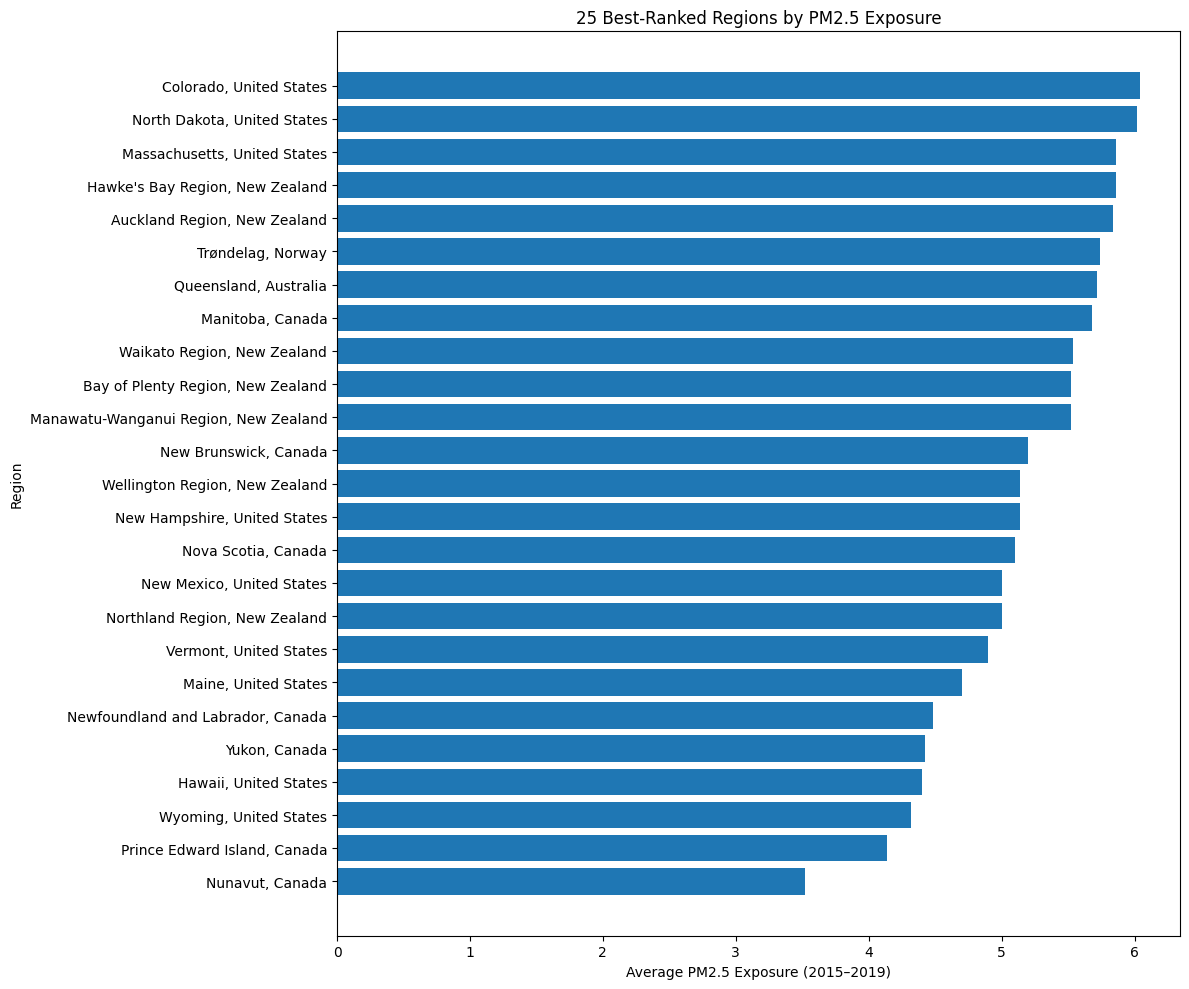

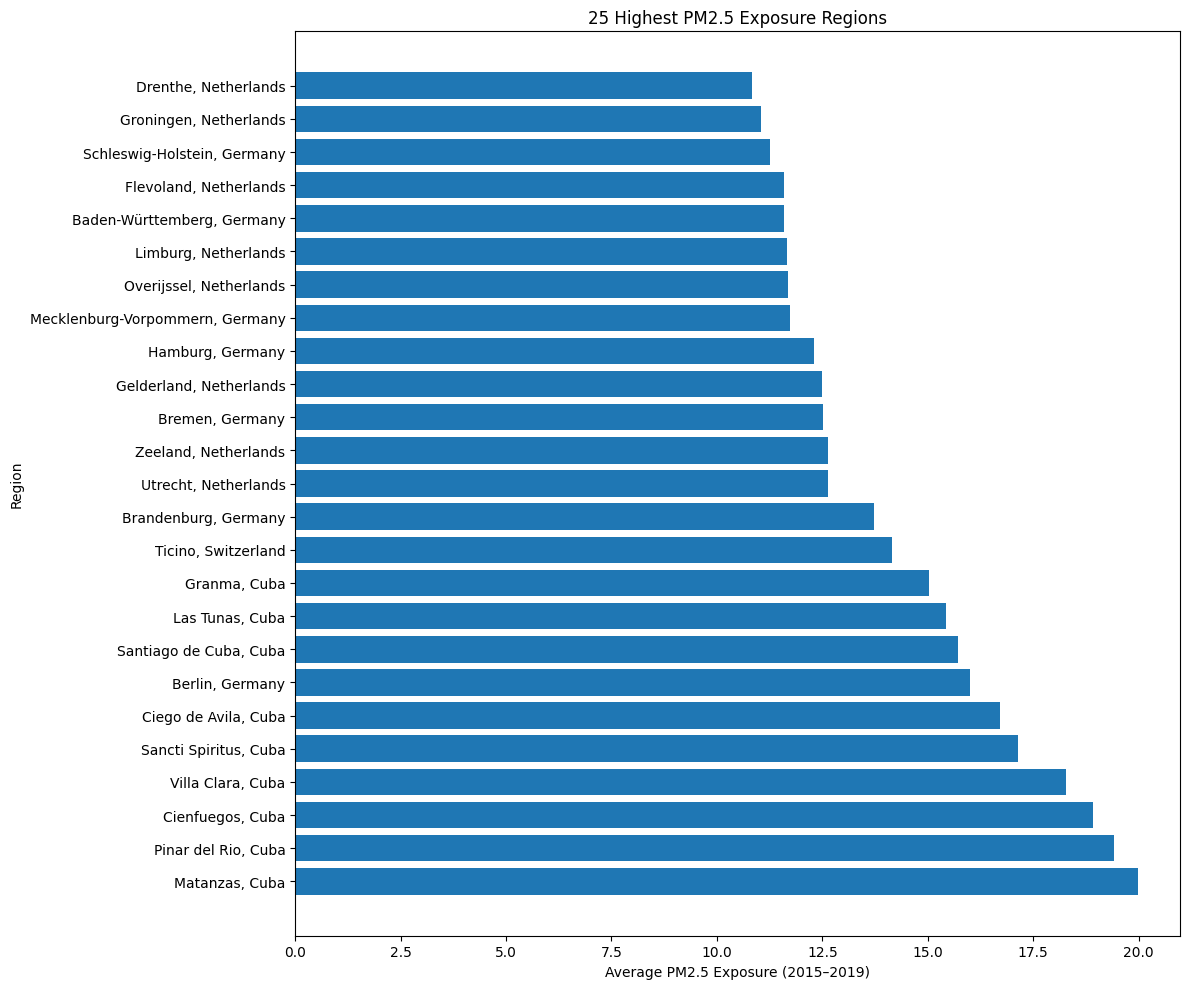


RANKING SUMMARY
Total ranked regions: 115
Lowest PM2.5: Nunavut Canada 3.5200000000000005
Highest PM2.5: Matanzas Cuba 19.98
Mean PM2.5: 8.41
Median PM2.5: 7.4

Exported:
HiMCM_Tier2_COMPLETE_PM25_RANKING.csv


In [157]:

# ============================================================
# CELL 12E: COMPLETE TIER 2 PM2.5 REGIONAL RANKING
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. VERIFY DATA
# ------------------------------------------------------------

if "PM25_REGIONAL" not in globals():
    raise NameError("Run Cell 12D first.")

ranking = PM25_REGIONAL.copy()

required_columns = [
    "country",
    "region",
    "pm25_mean_2015_2019"
]

for col in required_columns:
    if col not in ranking.columns:
        raise KeyError(f"Missing column: {col}")

# ------------------------------------------------------------
# 2. CLEAN DATA
# ------------------------------------------------------------

ranking["pm25_mean_2015_2019"] = pd.to_numeric(
    ranking["pm25_mean_2015_2019"],
    errors="coerce"
)

ranking = ranking.dropna(
    subset=["pm25_mean_2015_2019"]
)

ranking = ranking.drop_duplicates(
    subset=["country", "region"]
)

# ------------------------------------------------------------
# 3. RANK REGIONS
# ------------------------------------------------------------

# Lower PM2.5 exposure = better air quality.
ranking = ranking.sort_values(
    "pm25_mean_2015_2019",
    ascending=True
).reset_index(drop=True)

ranking["rank"] = (
    ranking["pm25_mean_2015_2019"]
    .rank(method="min", ascending=True)
    .astype(int)
)

ranking["air_quality_score"] = (
    100 * (
        1 -
        (
            ranking["pm25_mean_2015_2019"]
            - ranking["pm25_mean_2015_2019"].min()
        )
        /
        (
            ranking["pm25_mean_2015_2019"].max()
            - ranking["pm25_mean_2015_2019"].min()
        )
    )
)

ranking["air_quality_score"] = (
    ranking["air_quality_score"].round(2)
)

# ------------------------------------------------------------
# 4. FINAL RANKING TABLE
# ------------------------------------------------------------

FINAL_PM25_RANKING = ranking[
    [
        "rank",
        "region",
        "country",
        "pm25_mean_2015_2019",
        "air_quality_score"
    ]
].copy()

FINAL_PM25_RANKING.columns = [
    "Rank",
    "Region",
    "Country",
    "Average PM2.5 (2015–2019)",
    "Relative Air Quality Score"
]

print("=" * 85)
print("COMPLETE TIER 2 REGIONAL AIR QUALITY RANKING")
print("=" * 85)

print("Regions ranked:", len(FINAL_PM25_RANKING))
print("Rank 1 = lowest PM2.5 exposure")
print("Higher relative score = lower PM2.5 exposure")

# Display every region.
display(
    FINAL_PM25_RANKING.style.format({
        "Average PM2.5 (2015–2019)": "{:.2f}",
        "Relative Air Quality Score": "{:.2f}"
    })
)

# ------------------------------------------------------------
# 5. TOP 25 REGIONS GRAPH
# ------------------------------------------------------------

top25 = FINAL_PM25_RANKING.head(25).sort_values(
    "Average PM2.5 (2015–2019)",
    ascending=True
)

plt.figure(figsize=(12, 10))

plt.barh(
    top25["Region"] + ", " + top25["Country"],
    top25["Average PM2.5 (2015–2019)"]
)

plt.xlabel("Average PM2.5 Exposure (2015–2019)")
plt.ylabel("Region")
plt.title("25 Best-Ranked Regions by PM2.5 Exposure")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. BOTTOM 25 REGIONS GRAPH
# ------------------------------------------------------------

bottom25 = FINAL_PM25_RANKING.tail(25).sort_values(
    "Average PM2.5 (2015–2019)",
    ascending=False
)

plt.figure(figsize=(12, 10))

plt.barh(
    bottom25["Region"] + ", " + bottom25["Country"],
    bottom25["Average PM2.5 (2015–2019)"]
)

plt.xlabel("Average PM2.5 Exposure (2015–2019)")
plt.ylabel("Region")
plt.title("25 Highest PM2.5 Exposure Regions")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. SUMMARY STATISTICS
# ------------------------------------------------------------

print("\nRANKING SUMMARY")

print("Total ranked regions:", len(ranking))
print(
    "Lowest PM2.5:",
    ranking.iloc[0]["region"],
    ranking.iloc[0]["country"],
    ranking.iloc[0]["pm25_mean_2015_2019"]
)

print(
    "Highest PM2.5:",
    ranking.iloc[-1]["region"],
    ranking.iloc[-1]["country"],
    ranking.iloc[-1]["pm25_mean_2015_2019"]
)

print(
    "Mean PM2.5:",
    round(ranking["pm25_mean_2015_2019"].mean(), 2)
)

print(
    "Median PM2.5:",
    round(ranking["pm25_mean_2015_2019"].median(), 2)
)

# ------------------------------------------------------------
# 8. EXPORT
# ------------------------------------------------------------

FINAL_PM25_RANKING.to_csv(
    "HiMCM_Tier2_COMPLETE_PM25_RANKING.csv",
    index=False
)

print("\nExported:")
print("HiMCM_Tier2_COMPLETE_PM25_RANKING.csv")


In [164]:

# ============================================================
# COMPLETE CELL: TIER 2 REGIONAL DATA CLEANING AND MATCHING
# ============================================================
#
# FIXES:
# 1. Repairs homicide CSV parsing where possible.
# 2. Detects geographic columns using actual name overlap.
# 3. Fixes the KeyError caused by incorrect region lookup.
# 4. Handles country-name variations.
# 5. Matches regions using country + region where possible.
# 6. Does not assign national observations to individual regions.
# 7. Processes datasets independently; one failure cannot stop all.
# 8. Creates:
#       REGIONAL_INDICATOR_DATA
#       AVAILABLE_INDICATORS
#       MATCH_AUDIT
#       UNMATCHED_REGIONAL_ROWS
# ============================================================

import pandas as pd
import numpy as np
import re
import os
import csv
import unicodedata
import warnings

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. VERIFY INPUTS
# ------------------------------------------------------------

if "DATASETS" not in globals():
    raise NameError("DATASETS is missing. Run the loading cell first.")

if "REGIONAL_BOUNDARIES" not in globals():
    raise NameError("REGIONAL_BOUNDARIES is missing. Run the geometry cell first.")

if REGIONAL_BOUNDARIES.empty:
    raise ValueError("REGIONAL_BOUNDARIES is empty.")

print("=" * 75)
print("TIER 2 REGIONAL INDICATOR MATCHING")
print("=" * 75)

print("ADM1 boundary records:", len(REGIONAL_BOUNDARIES))
print("Available datasets:", list(DATASETS.keys()))


# ------------------------------------------------------------
# 2. STANDARDIZATION FUNCTIONS
# ------------------------------------------------------------

def clean_column_name(column):
    column = str(column).strip().lower()
    column = re.sub(r"[^a-z0-9]+", "_", column)
    return column.strip("_")


def normalize_place(value):

    if pd.isna(value):
        return ""

    value = str(value).strip().lower()

    value = unicodedata.normalize("NFKD", value)

    value = "".join(
        char for char in value
        if not unicodedata.combining(char)
    )

    value = value.replace("&", " and ")
    value = re.sub(r"[^a-z0-9]+", " ", value)
    value = re.sub(r"\s+", " ", value)

    return value.strip()


# Country aliases; these are used only for country matching.
COUNTRY_ALIASES = {
    "united states": "united states",
    "usa": "united states",
    "us": "united states",
    "united states of america": "united states",

    "united kingdom": "united kingdom",
    "uk": "united kingdom",
    "great britain": "united kingdom",

    "russian federation": "russia",
    "viet nam": "vietnam",
    "iran islamic republic of": "iran",
    "bolivia plurinational state of": "bolivia",
    "venezuela bolivarian republic of": "venezuela",
    "republic of korea": "south korea",
    "korea republic of": "south korea",
    "democratic peoples republic of korea": "north korea",

    "czechia": "czech republic",
    "the netherlands": "netherlands",
    "brunei darussalam": "brunei",
    "tanzania united republic of": "tanzania",
    "moldova republic of": "moldova"
}


def normalize_country(value):

    value = normalize_place(value)

    return COUNTRY_ALIASES.get(value, value)


# ------------------------------------------------------------
# 3. REPAIR HOM​​ICIDE CSV FILES
# ------------------------------------------------------------

HOMICIDE_FILES = {
    "homicide_1":
        "Intentional homicides (per 100,000 people) - Sheet1 (1).csv",

    "homicide_2":
        "Intentional homicides (per 100,000 people) - Sheet1.csv"
}


def parse_homicide_csv(filename):

    """
    Tries multiple delimiters and quote-handling methods.
    Returns a DataFrame only when a credible multi-column
    parse is found.

    Malformed rows are skipped only during fallback parsing.
    """

    if not os.path.exists(filename):
        raise FileNotFoundError(filename)

    candidates = []

    delimiters = [",", ";", "\t", "|"]

    # Attempt normal CSV parsing with multiple quote settings.
    for delimiter in delimiters:

        for quotechar in ['"', "'", None]:

            try:

                options = {
                    "filepath_or_buffer": filename,
                    "sep": delimiter,
                    "encoding": "utf-8-sig",
                    "engine": "python",
                    "on_bad_lines": "skip",
                    "skipinitialspace": True
                }

                if quotechar is None:
                    options["quoting"] = csv.QUOTE_NONE
                    options["escapechar"] = "\\"
                else:
                    options["quotechar"] = quotechar

                parsed = pd.read_csv(**options)

                parsed = parsed.dropna(axis=1, how="all")
                parsed = parsed.dropna(axis=0, how="all")

                if parsed.shape[1] >= 2 and len(parsed) > 0:

                    # Reject implausible parses with excessive columns.
                    if parsed.shape[1] > 100:
                        continue

                    score = (
                        len(parsed) *
                        min(parsed.shape[1], 20)
                    )

                    candidates.append(
                        (score, parsed, delimiter, quotechar)
                    )

            except Exception:
                pass

    # Fallback: manually unwrap rows that may have been
    # imported as a single quoted column.
    if not candidates:

        with open(
            filename,
            "r",
            encoding="utf-8-sig",
            errors="replace"
        ) as file:

            lines = [
                line.strip()
                for line in file
                if line.strip()
            ]

        for delimiter in delimiters:

            parsed_rows = []

            for line in lines:

                # Remove one enclosing quote pair if present.
                stripped = line.strip()

                if (
                    len(stripped) >= 2 and
                    stripped[0] == stripped[-1] and
                    stripped[0] in ['"', "'"]
                ):
                    stripped = stripped[1:-1]

                try:
                    row = next(
                        csv.reader(
                            [stripped],
                            delimiter=delimiter,
                            quotechar='"'
                        )
                    )
                except Exception:
                    row = stripped.split(delimiter)

                parsed_rows.append(row)

            if not parsed_rows:
                continue

            widths = pd.Series(
                [len(row) for row in parsed_rows]
            ).value_counts()

            expected_width = int(widths.index[0])

            # Require at least two columns and a consistent structure.
            if expected_width < 2:
                continue

            consistent_rows = [
                row for row in parsed_rows
                if len(row) == expected_width
            ]

            if len(consistent_rows) < 2:
                continue

            parsed = pd.DataFrame(
                consistent_rows[1:],
                columns=[
                    str(x).strip()
                    for x in consistent_rows[0]
                ]
            )

            if parsed.shape[1] >= 2:

                score = len(parsed) * min(parsed.shape[1], 20)

                candidates.append(
                    (score, parsed, delimiter, "manual")
                )

    if not candidates:
        raise ValueError(
            "No credible multi-column CSV structure was found. "
            "The file may genuinely contain only one column or "
            "may use a different export format."
        )

    candidates.sort(
        key=lambda item: item[0],
        reverse=True
    )

    _, best, delimiter, quotechar = candidates[0]

    # Validate that the first row is not entirely empty.
    best = best.dropna(axis=1, how="all")
    best = best.dropna(axis=0, how="all")

    if best.shape[1] < 2:
        raise ValueError("Parsed file still contains only one column.")

    return best, delimiter, quotechar


for dataset_name, filename in HOMICIDE_FILES.items():

    print(f"\nRepairing {dataset_name}...")

    try:

        repaired, delimiter, quotechar = parse_homicide_csv(filename)

        DATASETS[dataset_name] = repaired.copy()

        print("Successfully parsed.")
        print("Delimiter:", repr(delimiter))
        print("Quote setting:", quotechar)
        print("Dimensions:", repaired.shape)
        print("Columns:", repaired.columns.tolist())

        display(repaired.head(3))

    except Exception as error:

        print("Could not repair:", dataset_name)
        print("Reason:", str(error))
        print("Dataset will be excluded from matching.")

        # Do not let an unusable one-column file stop the cell.
        DATASETS[dataset_name] = pd.DataFrame()


# ------------------------------------------------------------
# 4. PREPARE BOUNDARY DATA
# ------------------------------------------------------------

BOUNDARIES = REGIONAL_BOUNDARIES.copy()

BOUNDARIES.columns = [
    clean_column_name(col)
    for col in BOUNDARIES.columns
]

def find_column(columns, candidates):

    columns = list(columns)

    # Exact matches first
    for candidate in candidates:
        if candidate in columns:
            return candidate

    # Partial matches second
    for column in columns:
        for candidate in candidates:
            if candidate in column:
                return column

    return None


BOUNDARY_REGION_COL = find_column(
    BOUNDARIES.columns,
    [
        "adm1_name",
        "admin1_name",
        "region_name",
        "province_name",
        "state_name",
        "region",
        "province",
        "state",
        "name_1"
    ]
)

BOUNDARY_COUNTRY_COL = find_column(
    BOUNDARIES.columns,
    [
        "country_name",
        "admin0_name",
        "adm0_name",
        "country",
        "nation",
        "admin0",
        "adm0"
    ]
)

print("\nBOUNDARY COLUMNS")
print("Region:", BOUNDARY_REGION_COL)
print("Country:", BOUNDARY_COUNTRY_COL)

if BOUNDARY_REGION_COL is None or BOUNDARY_COUNTRY_COL is None:
    raise ValueError(
        "Could not identify both ADM1 region and country columns. "
        f"Available columns: {BOUNDARIES.columns.tolist()}"
    )

# Reset index so all lookup values are guaranteed to be integer rows.
BOUNDARIES = BOUNDARIES.reset_index(drop=True)

BOUNDARIES["_region_key"] = (
    BOUNDARIES[BOUNDARY_REGION_COL].apply(normalize_place)
)

BOUNDARIES["_country_key"] = (
    BOUNDARIES[BOUNDARY_COUNTRY_COL].apply(normalize_country)
)

BOUNDARIES["_combined_key"] = (
    BOUNDARIES["_country_key"] + "|" +
    BOUNDARIES["_region_key"]
)

# A dictionary of combined geographic keys to boundary row indices.
COMBINED_LOOKUP = {}

for idx, row in BOUNDARIES.iterrows():

    key = row["_combined_key"]

    COMBINED_LOOKUP.setdefault(key, []).append(idx)

# A region-only dictionary; only unique names can be used.
REGION_LOOKUP = {}

for idx, row in BOUNDARIES.iterrows():

    key = row["_region_key"]

    if key:
        REGION_LOOKUP.setdefault(key, []).append(idx)

UNIQUE_REGION_LOOKUP = {
    key: indices[0]
    for key, indices in REGION_LOOKUP.items()
    if len(indices) == 1
}

print("\nBoundary lookup keys:", len(COMBINED_LOOKUP))
print("Unique region-only names:", len(UNIQUE_REGION_LOOKUP))


# ------------------------------------------------------------
# 5. GEOGRAPHIC COLUMN DETECTION BY ACTUAL NAME OVERLAP
# ------------------------------------------------------------

BOUNDARY_REGION_NAMES = set(
    BOUNDARIES["_region_key"].dropna()
)

BOUNDARY_COUNTRY_NAMES = set(
    BOUNDARIES["_country_key"].dropna()
)


def column_overlap_score(series, target_names, normalizer):

    values = series.dropna().astype(str).head(5000)

    if len(values) == 0:
        return 0, 0

    normalized = set(
        values.apply(normalizer).dropna()
    )

    normalized.discard("")

    if not normalized:
        return 0, 0

    overlap = normalized.intersection(target_names)

    return len(overlap), len(normalized)


def detect_geo_columns(df):

    region_candidates = []
    country_candidates = []

    for col in df.columns:

        # Skip geometry objects
        if col == "geometry":
            continue

        region_overlap, region_total = column_overlap_score(
            df[col],
            BOUNDARY_REGION_NAMES,
            normalize_place
        )

        country_overlap, country_total = column_overlap_score(
            df[col],
            BOUNDARY_COUNTRY_NAMES,
            normalize_country
        )

        # Region columns should overlap actual ADM1 names.
        if region_overlap > 0:
            region_candidates.append(
                (region_overlap, region_total, col)
            )

        # Country columns should overlap country names.
        if country_overlap > 0:
            country_candidates.append(
                (country_overlap, country_total, col)
            )

    region_col = (
        sorted(region_candidates, reverse=True)[0][2]
        if region_candidates else None
    )

    country_col = (
        sorted(country_candidates, reverse=True)[0][2]
        if country_candidates else None
    )

    # Do not use one column for both roles.
    if region_col == country_col:
        region_col = None

    return region_col, country_col, region_candidates, country_candidates


# ------------------------------------------------------------
# 6. IDENTIFY VALUE, YEAR, AND INDICATOR COLUMNS
# ------------------------------------------------------------

NON_INDICATOR_TERMS = [
    "latitude",
    "longitude",
    "coordinate",
    "geometry",
    "shape",
    "objectid",
    "fid",
    "iso",
    "code",
    "identifier",
    "rank",
    "year",
    "time",
    "date",
    "period",
    "population_total"
]

VALUE_TERMS = [
    "value",
    "obs_value",
    "estimate",
    "rate",
    "percentage",
    "percent",
    "share",
    "index",
    "score",
    "mean",
    "average",
    "total"
]


def detect_year_column(df):

    candidates = [
        "year",
        "time",
        "reference_year",
        "ref_year",
        "period",
        "time_period"
    ]

    return find_column(df.columns, candidates)


def detect_indicator_column(df):

    candidates = [
        "indicator",
        "indicator_name",
        "series",
        "series_name",
        "measure",
        "metric"
    ]

    return find_column(df.columns, candidates)


def detect_value_columns(df, geo_columns):

    value_columns = []

    for col in df.columns:

        if col in geo_columns or col is None:
            continue

        name = col.lower()

        if any(term in name for term in NON_INDICATOR_TERMS):
            continue

        numeric = pd.to_numeric(
            df[col].astype(str).str.replace(",", "", regex=False),
            errors="coerce"
        )

        valid_count = numeric.notna().sum()

        if valid_count == 0:
            continue

        # Exclude columns that are almost entirely identifiers.
        valid_fraction = valid_count / max(len(df), 1)

        if valid_fraction < 0.05:
            continue

        value_columns.append(col)

    # If there are explicit value fields, prefer those.
    preferred = [
        col for col in value_columns
        if any(term in col.lower() for term in VALUE_TERMS)
    ]

    if preferred:
        return preferred

    return value_columns


# ------------------------------------------------------------
# 7. MATCH REGION AND COUNTRY SAFELY
# ------------------------------------------------------------

def match_boundary(region_value, country_value=None):

    region_key = normalize_place(region_value)

    if not region_key:
        return None

    country_key = normalize_country(country_value)

    # First preference: exact country + region
    if country_key:

        combined_key = country_key + "|" + region_key

        candidates = COMBINED_LOOKUP.get(combined_key, [])

        if len(candidates) == 1:
            return candidates[0]

        # Ambiguous country-region key is not accepted.
        if len(candidates) > 1:
            return None

    # Second preference: region-only match, but only if unique.
    return UNIQUE_REGION_LOOKUP.get(region_key)


# ------------------------------------------------------------
# 8. PROCESS ONE DATASET
# ------------------------------------------------------------

def process_regional_dataset(dataset_name, original_df):

    audit = {
        "dataset": dataset_name,
        "input_rows": len(original_df),
        "region_column": None,
        "country_column": None,
        "region_column_overlap": 0,
        "country_column_overlap": 0,
        "value_columns": "",
        "matched_rows": 0,
        "unmatched_rows": 0,
        "output_indicators": 0,
        "status": ""
    }

    if original_df is None or original_df.empty:
        audit["status"] = "EMPTY OR UNREADABLE DATASET"
        return pd.DataFrame(), audit, pd.DataFrame()

    df = original_df.copy()

    df.columns = [
        clean_column_name(col)
        for col in df.columns
    ]

    # Identify geography based on actual overlap with boundaries.
    region_col, country_col, region_candidates, country_candidates = (
        detect_geo_columns(df)
    )

    audit["region_column"] = region_col
    audit["country_column"] = country_col

    if region_candidates:
        audit["region_column_overlap"] = (
            sorted(region_candidates, reverse=True)[0][0]
        )

    if country_candidates:
        audit["country_column_overlap"] = (
            sorted(country_candidates, reverse=True)[0][0]
        )

    if region_col is None:
        audit["status"] = "NO ADM1 REGION NAME MATCHES"
        return pd.DataFrame(), audit, df.head(20)

    geo_columns = {region_col, country_col}

    value_columns = detect_value_columns(
        df,
        geo_columns
    )

    audit["value_columns"] = ", ".join(value_columns)

    if not value_columns:
        audit["status"] = "NO NUMERIC INDICATOR COLUMNS"
        return pd.DataFrame(), audit, df.head(20)

    year_col = detect_year_column(df)
    indicator_col = detect_indicator_column(df)

    # Match every source row to a boundary row.
    matched_indices = []
    matched_names = []
    matched_countries = []

    for _, row in df.iterrows():

        country_value = (
            row[country_col]
            if country_col is not None else None
        )

        boundary_idx = match_boundary(
            row[region_col],
            country_value
        )

        matched_indices.append(boundary_idx)

        if boundary_idx is None:
            matched_names.append(None)
            matched_countries.append(None)

        else:
            matched_names.append(
                BOUNDARIES.loc[
                    boundary_idx,
                    BOUNDARY_REGION_COL
                ]
            )

            matched_countries.append(
                BOUNDARIES.loc[
                    boundary_idx,
                    BOUNDARY_COUNTRY_COL
                ]
            )

    df["_boundary_idx"] = matched_indices
    df["_matched_region"] = matched_names
    df["_matched_country"] = matched_countries

    matched = df[df["_boundary_idx"].notna()].copy()

    unmatched = df[df["_boundary_idx"].isna()].copy()

    audit["matched_rows"] = len(matched)
    audit["unmatched_rows"] = len(unmatched)

    if matched.empty:
        audit["status"] = "NO GEOGRAPHIC MATCHES"
        return pd.DataFrame(), audit, unmatched.head(20)

    output_frames = []

    for value_col in value_columns:

        temp = matched.copy()

        # Convert numeric values; remove commas from formatted numbers.
        temp["value"] = pd.to_numeric(
            temp[value_col].astype(str).str.replace(
                ",", "", regex=False
            ),
            errors="coerce"
        )

        temp = temp.dropna(subset=["value"])

        temp = temp[
            np.isfinite(temp["value"])
        ].copy()

        if temp.empty:
            continue

        if indicator_col is not None:

            labels = (
                temp[indicator_col]
                .fillna(value_col)
                .astype(str)
                .str.strip()
            )

            # Retain source-column identity when multiple value
            # columns exist.
            if len(value_columns) > 1:
                labels = dataset_name + "_" + value_col + "_" + labels

            else:
                labels = dataset_name + "_" + labels

        else:
            labels = dataset_name + "_" + value_col

        temp["indicator"] = labels

        temp["location"] = temp["_matched_region"]
        temp["country"] = temp["_matched_country"]
        temp["source"] = dataset_name
        temp["tier"] = "Tier 2"

        if year_col is not None:
            temp["year"] = temp[year_col]
        else:
            temp["year"] = np.nan

        output_frames.append(
            temp[
                [
                    "tier",
                    "country",
                    "location",
                    "indicator",
                    "value",
                    "year",
                    "source"
                ]
            ]
        )

    if not output_frames:
        audit["status"] = "MATCHED REGIONS BUT NO VALID VALUES"
        return pd.DataFrame(), audit, unmatched.head(20)

    result = pd.concat(
        output_frames,
        ignore_index=True
    )

    audit["output_indicators"] = result["indicator"].nunique()
    audit["status"] = "SUCCESS"

    return result, audit, unmatched.head(20)


# ------------------------------------------------------------
# 9. PROCESS EVERY DATASET WITHOUT STOPPING ON ERRORS
# ------------------------------------------------------------

REGIONAL_RESULTS = []
AUDIT_RESULTS = []
UNMATCHED_RESULTS = []

for dataset_name, df in DATASETS.items():

    print(f"\nProcessing: {dataset_name}")

    try:

        result, audit, unmatched = process_regional_dataset(
            dataset_name,
            df
        )

        AUDIT_RESULTS.append(audit)

        if not result.empty:
            REGIONAL_RESULTS.append(result)

        if not unmatched.empty:
            unmatched = unmatched.copy()
            unmatched["source_dataset"] = dataset_name
            UNMATCHED_RESULTS.append(unmatched)

        print("Status:", audit["status"])
        print("Input rows:", audit["input_rows"])
        print("Region column:", audit["region_column"])
        print("Country column:", audit["country_column"])
        print("Matched rows:", audit["matched_rows"])
        print("Unmatched rows:", audit["unmatched_rows"])
        print("Indicators:", audit["output_indicators"])

    except Exception as error:

        print("DATASET PROCESSING ERROR:", dataset_name)
        print("Reason:", repr(error))

        AUDIT_RESULTS.append({
            "dataset": dataset_name,
            "input_rows": len(df) if isinstance(df, pd.DataFrame) else 0,
            "region_column": None,
            "country_column": None,
            "region_column_overlap": 0,
            "country_column_overlap": 0,
            "value_columns": "",
            "matched_rows": 0,
            "unmatched_rows": 0,
            "output_indicators": 0,
            "status": "PROCESSING ERROR: " + str(error)[:150]
        })


# ------------------------------------------------------------
# 10. COMBINE RESULTS
# ------------------------------------------------------------

OUTPUT_COLUMNS = [
    "tier",
    "country",
    "location",
    "indicator",
    "value",
    "year",
    "source"
]

if REGIONAL_RESULTS:

    REGIONAL_INDICATOR_DATA = pd.concat(
        REGIONAL_RESULTS,
        ignore_index=True
    )

else:

    REGIONAL_INDICATOR_DATA = pd.DataFrame(
        columns=OUTPUT_COLUMNS
    )


# ------------------------------------------------------------
# 11. CLEAN FINAL OBSERVATIONS
# ------------------------------------------------------------

if not REGIONAL_INDICATOR_DATA.empty:

    REGIONAL_INDICATOR_DATA["value"] = pd.to_numeric(
        REGIONAL_INDICATOR_DATA["value"],
        errors="coerce"
    )

    REGIONAL_INDICATOR_DATA = (
        REGIONAL_INDICATOR_DATA
        .dropna(
            subset=[
                "location",
                "indicator",
                "value"
            ]
        )
        .copy()
    )

    REGIONAL_INDICATOR_DATA = (
        REGIONAL_INDICATOR_DATA[
            np.isfinite(REGIONAL_INDICATOR_DATA["value"])
        ]
    )

    # Combine duplicate observations only within the same source,
    # year, country, region, and indicator.
    REGIONAL_INDICATOR_DATA = (
        REGIONAL_INDICATOR_DATA
        .groupby(
            [
                "tier",
                "country",
                "location",
                "indicator",
                "year",
                "source"
            ],
            dropna=False,
            as_index=False
        )["value"]
        .mean()
    )

REGIONAL_INDICATOR_DATA = (
    REGIONAL_INDICATOR_DATA
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 12. CREATE OUTPUT VARIABLES
# ------------------------------------------------------------

AVAILABLE_INDICATORS = sorted(
    REGIONAL_INDICATOR_DATA["indicator"]
    .dropna()
    .unique()
    .tolist()
)

MATCH_AUDIT = pd.DataFrame(AUDIT_RESULTS)

if UNMATCHED_RESULTS:
    UNMATCHED_REGIONAL_ROWS = pd.concat(
        UNMATCHED_RESULTS,
        ignore_index=True
    )
else:
    UNMATCHED_REGIONAL_ROWS = pd.DataFrame()


# ------------------------------------------------------------
# 13. FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL TIER 2 REGIONAL MATCHING RESULTS")
print("=" * 75)

print("ADM1 boundary records:", len(BOUNDARIES))

print(
    "Matched regions:",
    REGIONAL_INDICATOR_DATA["location"].nunique()
    if not REGIONAL_INDICATOR_DATA.empty else 0
)

print(
    "Matched observations:",
    len(REGIONAL_INDICATOR_DATA)
)

print(
    "Available indicators:",
    len(AVAILABLE_INDICATORS)
)

print("\nMATCH AUDIT")
display(MATCH_AUDIT)

print("\nAVAILABLE INDICATORS")
for indicator in AVAILABLE_INDICATORS:
    print("-", indicator)

print("\nREGIONAL DATA PREVIEW")
display(REGIONAL_INDICATOR_DATA.head(20))

if not REGIONAL_INDICATOR_DATA.empty:

    print("\nRESULTS BY DATASET")

    display(
        REGIONAL_INDICATOR_DATA.groupby("source")
        .agg(
            observations=("value", "count"),
            regions=("location", "nunique"),
            indicators=("indicator", "nunique")
        )
        .sort_values(
            "observations",
            ascending=False
        )
    )

    print("\nRESULTS BY REGION")

    display(
        REGIONAL_INDICATOR_DATA.groupby("location")
        .agg(
            observations=("value", "count"),
            indicators=("indicator", "nunique")
        )
        .sort_values(
            "indicators",
            ascending=False
        )
        .head(20)
    )

else:

    print(
        "\nWARNING: No valid regional observations were produced. "
        "Review MATCH_AUDIT before scoring."
    )

print("\nUnmatched row samples:")
if not UNMATCHED_REGIONAL_ROWS.empty:
    display(UNMATCHED_REGIONAL_ROWS.head(30))
else:
    print("No unmatched rows were recorded.")

print("\nCELL FINISHED.")


TIER 2 REGIONAL INDICATOR MATCHING
ADM1 boundary records: 228
Available datasets: ['public_space', 'homicide_1', 'aqi', 'corruption', 'violent_crime', 'public_transport', 'healthcare', 'pm25', 'homicide_2', 'higher_education']

Repairing homicide_1...
Could not repair: homicide_1
Reason: No credible multi-column CSV structure was found. The file may genuinely contain only one column or may use a different export format.
Dataset will be excluded from matching.

Repairing homicide_2...
Could not repair: homicide_2
Reason: No credible multi-column CSV structure was found. The file may genuinely contain only one column or may use a different export format.
Dataset will be excluded from matching.

BOUNDARY COLUMNS
Region: region
Country: country

Boundary lookup keys: 228
Unique region-only names: 228

Processing: public_space
Status: SUCCESS
Input rows: 3663
Region column: city_name
Country column: country_or_territory_name
Matched rows: 33
Unmatched rows: 3630
Indicators: 2

Processing: h

,dataset,input_rows,region_column,country_column,region_column_overlap,country_column_overlap,value_columns,matched_rows,unmatched_rows,output_indicators,status
0,public_space,3663,city_name,country_or_territory_name,20,14,average_share_of_the_built_up_area_of_cities_t...,33,3630,2,SUCCESS
1,homicide_1,0,None,None,0,0,,0,0,0,EMPTY OR UNREADABLE DATASET
2,aqi,16695,city,country,8,11,"aqi_value, co_aqi_value, ozone_aqi_value, no2_...",71,16624,5,SUCCESS
3,corruption,27081,None,unodc_stats_un_org,3,13,,0,0,0,NO ADM1 REGION NAME MATCHES
4,violent_crime,34976,None,unodc_stats_un_org,0,2,,0,0,0,NO ADM1 REGION NAME MATCHES
5,public_transport,2927,city_name,geoareaname,24,14,share_of_urban_population_with_convenient_acce...,47,2880,1,SUCCESS
6,healthcare,1727,None,ref_area_label,1,14,,0,0,0,NO ADM1 REGION NAME MATCHES
7,pm25,2686,unnamed_1,mean_population_exposure_to_pm2_5_micrograms_m...,123,16,"unnamed_3, unnamed_4, unnamed_5, unnamed_6, un...",125,2561,5,SUCCESS
8,homicide_2,0,None,None,0,0,,0,0,0,EMPTY OR UNREADABLE DATASET
9,higher_education,271,None,country_name,4,16,,0,0,0,NO ADM1 REGION NAME MATCHES



AVAILABLE INDICATORS
- aqi_aqi_value
- aqi_co_aqi_value
- aqi_no2_aqi_value
- aqi_ozone_aqi_value
- aqi_pm2_5_aqi_value
- pm25_unnamed_3
- pm25_unnamed_4
- pm25_unnamed_5
- pm25_unnamed_6
- pm25_unnamed_7
- public_space_average_share_of_the_built_up_area_of_cities_that_is_open_space_for_public_use_for_all_a_11.7.1
- public_space_average_share_of_urban_population_with_convenient_access_to_open_public_spaces_b_11.7.1
- public_transport_11.2.1

REGIONAL DATA PREVIEW


,tier,country,location,indicator,year,source,value
0,Tier 2,Australia,Australian Capital Territory,pm25_unnamed_3,NaN,pm25,6.2
1,Tier 2,Australia,Australian Capital Territory,pm25_unnamed_4,NaN,pm25,6.4
2,Tier 2,Australia,Australian Capital Territory,pm25_unnamed_5,NaN,pm25,6.1
3,Tier 2,Australia,Australian Capital Territory,pm25_unnamed_6,NaN,pm25,6.1
4,Tier 2,Australia,Australian Capital Territory,pm25_unnamed_7,NaN,pm25,6.1
5,Tier 2,Australia,New South Wales,pm25_unnamed_3,NaN,pm25,6.9
6,Tier 2,Australia,New South Wales,pm25_unnamed_4,NaN,pm25,7.0
7,Tier 2,Australia,New South Wales,pm25_unnamed_5,NaN,pm25,6.7
8,Tier 2,Australia,New South Wales,pm25_unnamed_6,NaN,pm25,6.9
9,Tier 2,Australia,New South Wales,pm25_unnamed_7,NaN,pm25,6.9



RESULTS BY DATASET


,observations,regions,indicators
source,,,
pm25,615,123,5
aqi,165,33,5
public_space,55,20,2
public_transport,47,24,1



RESULTS BY REGION


,observations,indicators
location,,
Utrecht,15,13
New York,13,13
Montana,13,13
Hamburg,15,13
Cienfuegos,13,13
Bremen,15,13
Berlin,16,13
Victoria,18,13
Groningen,12,12



Unmatched row samples:


,sdg_goal,sdg_target,sdg_indicator,country_or_territory_code,country_or_territory_name,sdg_region,sdg_sub_region,city_code,city_name,average_share_of_the_built_up_area_of_cities_that_is_open_space_for_public_use_for_all_a,average_share_of_urban_population_with_convenient_access_to_open_public_spaces_b,data_units,data_reference_year,data_source,footnote,_boundary_idx,_matched_region,_matched_country,source_dataset,country,city,aqi_value,aqi_category,co_aqi_value,co_aqi_category,ozone_aqi_value,ozone_aqi_category,no2_aqi_value,no2_aqi_category,pm2_5_aqi_value,pm2_5_aqi_category,lat,lng,unodc,unodc_stats_un_org,unnamed_2,unnamed_3,unnamed_4,unnamed_5,unnamed_6,unnamed_7,unnamed_8,unnamed_9,unnamed_10,unnamed_11,unnamed_12,geoareacode,geoareaname,share_of_urban_population_with_convenient_access_to_public_transport,units,...,unit_measure,comp_breakdown_1,comp_breakdown_2,comp_breakdown_3,time_period,obs_value,agg_method,unit_type,decimals,database_id,time_format,unit_mult,obs_status,obs_conf,freq_label,ref_area_label,indicator_label,sex_label,age_label,urbanisation_label,unit_measure_label,comp_breakdown_1_label,comp_breakdown_2_label,comp_breakdown_3_label,agg_method_label,unit_type_label,decimals_label,database_id_label,time_format_label,unit_mult_label,obs_status_label,obs_conf_label,mean_population_exposure_to_pm2_5_micrograms_m3_air_pollution,unnamed_1,series_name,series_code,country_name,country_code,1990_yr1990,2000_yr2000,2016_yr2016,2017_yr2017,2018_yr2018,2019_yr2019,2020_yr2020,2021_yr2021,2022_yr2022,2023_yr2023,2024_yr2024,2025_yr2025
0,11.0,11.7,11.7.1,4.0,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_KABUL,Kabul,19.2,NaN,PERCENT,2025.0,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...,NaN,None,None,public_space,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,11.0,11.7,11.7.1,4.0,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_CHARIKAR,Chārīkār,17.9,82.1,PERCENT,2020.0,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...,NaN,None,None,public_space,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,11.0,11.7,11.7.1,4.0,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_FARAH,Farāh,12.1,62.5,PERCENT,2020.0,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...,NaN,None,None,public_space,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,11.0,11.7,11.7.1,4.0,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_HERAT,Herat,17.2,55.6,PERCENT,2020.0,UN-Habitat Urban Indicators Database,[a] Calculated as the proportion of urban area...,NaN,None,None,public_space,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,11.0,11.7,11.7.1,4.0,Afghanistan,Central Asia and Southern Asia,Southern Asia,AF_JALALABAD,Jalālābād,15.7,59.0,PERCENT,2020.0,UN-Habitat Urban Indicators Database,[a] Calculate


CELL FINISHED.


TIER 2 REGIONAL SCORING
Regions: 135
Indicators: 13
Observations: 843

INDICATOR DIRECTIONS


,indicator,direction
0,pm25_unnamed_3,cost
1,pm25_unnamed_4,cost
2,pm25_unnamed_5,cost
3,pm25_unnamed_6,cost
4,pm25_unnamed_7,cost
5,aqi_aqi_value,cost
6,aqi_co_aqi_value,cost
7,aqi_no2_aqi_value,cost
8,aqi_ozone_aqi_value,cost
9,aqi_pm2_5_aqi_value,cost



Raw regional matrix: (135, 13)

NORMALIZATION AUDIT


,indicator,minimum_raw_value,maximum_raw_value,direction
0,aqi_aqi_value,26.00,160.00,cost
1,aqi_co_aqi_value,0.00,4.00,cost
2,aqi_no2_aqi_value,0.00,33.00,cost
3,aqi_ozone_aqi_value,3.00,43.00,cost
4,aqi_pm2_5_aqi_value,14.00,160.00,cost
5,pm25_unnamed_3,3.40,63.70,cost
6,pm25_unnamed_4,3.20,59.30,cost
7,pm25_unnamed_5,3.70,59.10,cost
8,pm25_unnamed_6,3.60,57.80,cost
9,pm25_unnamed_7,3.70,56.50,cost



OBJECTIVE ENTROPY WEIGHTS


,indicator,entropy,divergence,weight
0,public_space_average_share_of_the_built_up_are...,0.985045,0.014955,0.233723
1,aqi_ozone_aqi_value,0.989129,0.010871,0.169907
2,public_space_average_share_of_urban_population...,0.994239,0.005761,0.090038
3,public_transport_11.2.1,0.995106,0.004894,0.076485
4,aqi_co_aqi_value,0.995759,0.004241,0.066284
5,aqi_no2_aqi_value,0.996938,0.003062,0.047853
6,aqi_pm2_5_aqi_value,0.996986,0.003014,0.047103
7,pm25_unnamed_4,0.997001,0.002999,0.046866
8,aqi_aqi_value,0.997123,0.002877,0.044970
9,pm25_unnamed_3,0.997126,0.002874,0.044912



FINAL TIER 2 REGIONAL RANKING


,rank,country,location,regional_score_100,raw_composite_score,data_coverage,indicators_available,indicators_total
0,1,Canada,Nunavut,100.00,1.0000,22.36%,5,13
1,2,Canada,Prince Edward Island,98.91,0.9891,22.36%,5,13
2,3,United States,Hawaii,98.42,0.9842,22.36%,5,13
3,4,Canada,Newfoundland and Labrador,98.29,0.9829,22.36%,5,13
4,5,United States,Maine,97.89,0.9789,22.36%,5,13
5,6,United States,Vermont,97.53,0.9753,22.36%,5,13
6,7,United States,New Mexico,97.35,0.9735,22.36%,5,13
7,8,New Zealand,Northland Region,97.34,0.9734,22.36%,5,13
8,9,Canada,Nova Scotia,97.18,0.9718,22.36%,5,13
9,10,United States,New Hampshire,97.10,0.9710,22.36%,5,13


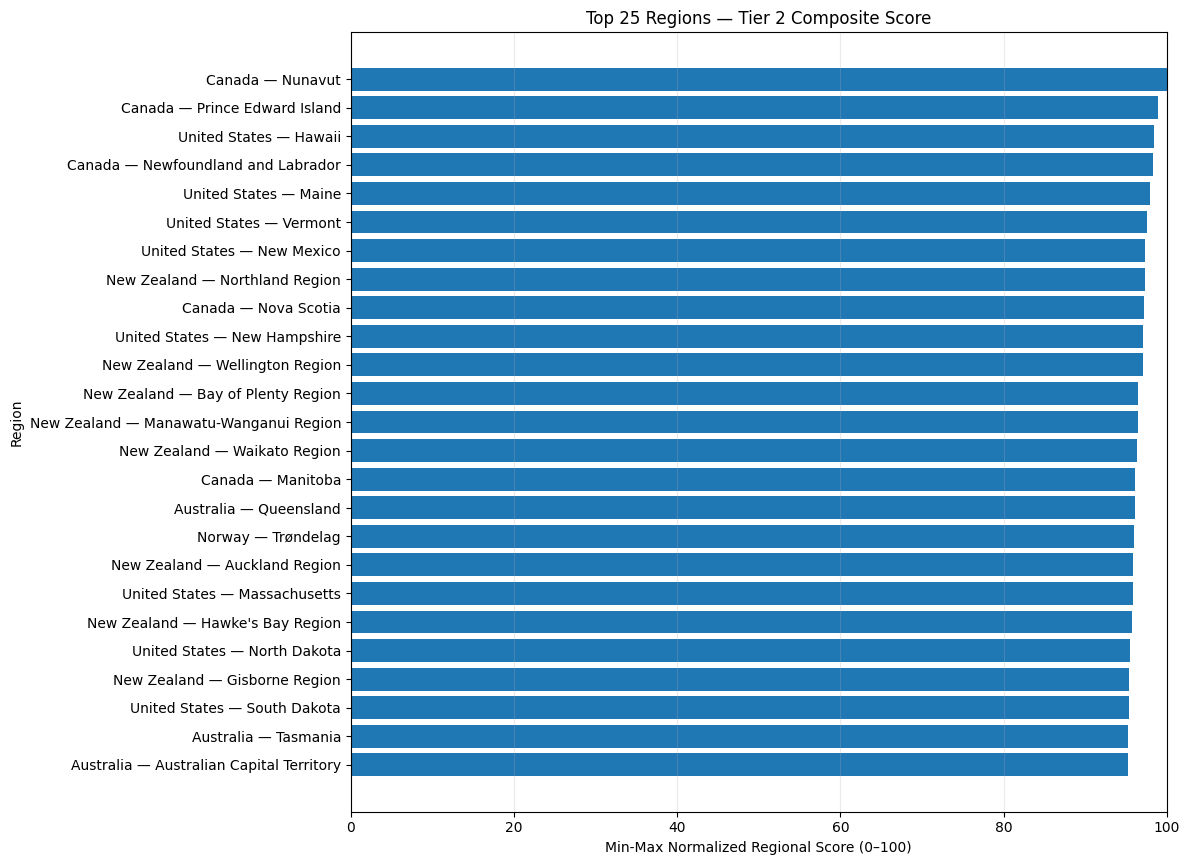

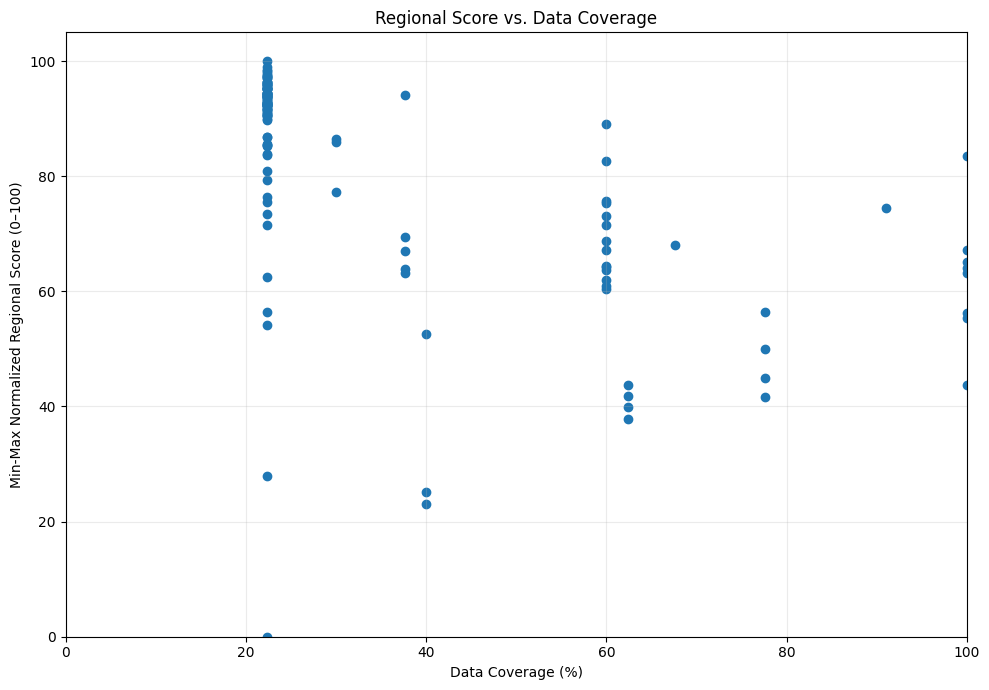

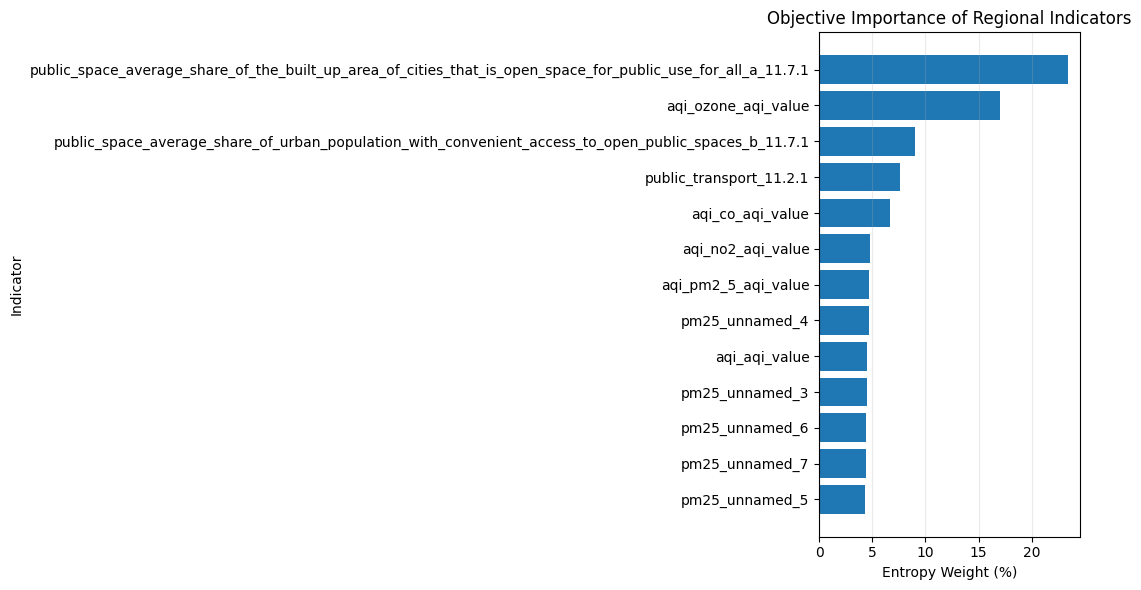


FILES EXPORTED:
- Tier_2_Regional_Ranking.csv
- Tier_2_Regional_Entropy_Weights.csv
- Tier_2_Regional_Normalized_Indicators.csv

TIER 2 REGIONAL SCORING COMPLETE.


In [165]:

# ============================================================
# CELL: TIER 2 REGIONAL SCORING, MIN-MAX NORMALIZATION,
#       RANKING, AND VISUALIZATION
# ============================================================
#
# OUTPUTS:
#   1. REGIONAL_NORMALIZED_DATA
#   2. REGIONAL_ENTROPY_WEIGHTS
#   3. REGIONAL_SCORES
#   4. REGIONAL_RANKING
#   5. Graphs showing regional performance
#   6. Complete regional ranking table
#
# SCORE INTERPRETATION:
#   0   = Lowest composite score among evaluated regions
#   100 = Highest composite score among evaluated regions
#
# IMPORTANT:
#   Edit INDICATOR_DIRECTIONS below if an indicator's
#   direction is not correctly identified automatically.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import warnings

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. VERIFY INPUT DATA
# ------------------------------------------------------------

if "REGIONAL_INDICATOR_DATA" not in globals():
    raise NameError(
        "REGIONAL_INDICATOR_DATA is missing. "
        "Run the Tier 2 regional matching cell first."
    )

df = REGIONAL_INDICATOR_DATA.copy()

required_columns = [
    "location", "indicator", "value"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

if df.empty:
    raise ValueError(
        "REGIONAL_INDICATOR_DATA is empty. "
        "Regional scoring cannot proceed."
    )

# ------------------------------------------------------------
# 2. CLEAN THE DATA
# ------------------------------------------------------------

df["location"] = df["location"].astype(str).str.strip()
df["indicator"] = df["indicator"].astype(str).str.strip()
df["value"] = pd.to_numeric(df["value"], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)

df = df.dropna(
    subset=["location", "indicator", "value"]
).copy()

# Preserve country identity so that regions with the same
# name in different countries are not accidentally combined.

if "country" not in df.columns:
    df["country"] = "Unknown"

df["country"] = (
    df["country"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

df["region_id"] = (
    df["country"] + " | " + df["location"]
)

# Remove exact duplicate observations.
df = df.drop_duplicates(
    subset=[
        "region_id",
        "indicator",
        "value",
        "year",
        "source"
    ] if "year" in df.columns and "source" in df.columns
    else ["region_id", "indicator", "value"]
)

# If multiple sources or observations remain for the same
# region and indicator, combine them using their mean.
# This is an aggregation step, not an assumption that
# different years are interchangeable.
#
# If your data includes multiple years, select a consistent
# reference year before this cell whenever possible.

regional_values = (
    df.groupby(
        ["region_id", "country", "location", "indicator"],
        as_index=False
    )["value"]
    .mean()
)

print("=" * 70)
print("TIER 2 REGIONAL SCORING")
print("=" * 70)

print("Regions:", regional_values["region_id"].nunique())
print("Indicators:", regional_values["indicator"].nunique())
print("Observations:", len(regional_values))

# ------------------------------------------------------------
# 3. DEFINE INDICATOR DIRECTIONS
# ------------------------------------------------------------
#
# benefit = higher value is better
# cost    = lower value is better
#
# You can override the automatic classification below.
# Use the exact indicator names printed in the output.
# ------------------------------------------------------------

INDICATOR_DIRECTIONS = {}

# Examples of manual overrides:
#
# INDICATOR_DIRECTIONS["aqi"] = "cost"
# INDICATOR_DIRECTIONS["pm25"] = "cost"
# INDICATOR_DIRECTIONS["homicide_1_value"] = "cost"
# INDICATOR_DIRECTIONS["higher_education_value"] = "benefit"

def infer_direction(indicator):
    name = str(indicator).lower()

    # Lower values are generally better for these measures.
    cost_keywords = [
        "homicide",
        "violent_crime",
        "violent crime",
        "sexual_crime",
        "sexual crime",
        "corruption_cases",
        "corruption_and_economic_crime",
        "crime_rate",
        "crime rate",
        "aqi",
        "pm25",
        "pm2.5",
        "pollution",
        "mortality",
        "poverty",
        "unemployment",
        "exposure"
    ]

    # Higher values are generally better for these measures.
    benefit_keywords = [
        "public_space",
        "public space",
        "public_transport",
        "public transport",
        "healthcare",
        "higher_education",
        "higher education",
        "education",
        "service_coverage",
        "coverage",
        "access",
        "accessibility",
        "green_space",
        "green space"
    ]

    if any(keyword in name for keyword in cost_keywords):
        return "cost"

    if any(keyword in name for keyword in benefit_keywords):
        return "benefit"

    # Unknown directions are deliberately not guessed.
    return "UNCONFIRMED"


directions = {}

for indicator in regional_values["indicator"].unique():

    if indicator in INDICATOR_DIRECTIONS:
        direction = INDICATOR_DIRECTIONS[indicator]
    else:
        direction = infer_direction(indicator)

    if direction not in ["benefit", "cost"]:
        raise ValueError(
            f"Direction not confirmed for indicator: {indicator}\n"
            "Add it to INDICATOR_DIRECTIONS as 'benefit' or 'cost'."
        )

    directions[indicator] = direction

print("\nINDICATOR DIRECTIONS")

direction_table = pd.DataFrame([
    {
        "indicator": indicator,
        "direction": direction
    }
    for indicator, direction in directions.items()
])

display(direction_table)

# ------------------------------------------------------------
# 4. PIVOT INTO REGION-BY-INDICATOR MATRIX
# ------------------------------------------------------------

REGIONAL_RAW_MATRIX = regional_values.pivot_table(
    index=["region_id", "country", "location"],
    columns="indicator",
    values="value",
    aggfunc="mean"
)

REGIONAL_RAW_MATRIX = REGIONAL_RAW_MATRIX.sort_index(axis=1)

print("\nRaw regional matrix:", REGIONAL_RAW_MATRIX.shape)

# ------------------------------------------------------------
# 5. MIN-MAX NORMALIZE EACH INDICATOR
# ------------------------------------------------------------

REGIONAL_NORMALIZED_DATA = REGIONAL_RAW_MATRIX.copy()

indicator_minmax = []

for indicator in REGIONAL_RAW_MATRIX.columns:

    values = pd.to_numeric(
        REGIONAL_RAW_MATRIX[indicator],
        errors="coerce"
    )

    minimum = values.min()
    maximum = values.max()

    if pd.isna(minimum) or pd.isna(maximum):
        REGIONAL_NORMALIZED_DATA[indicator] = np.nan
        continue

    if maximum == minimum:
        # No variation means this indicator cannot distinguish
        # between regions; assign a neutral value.
        normalized = pd.Series(
            0.5,
            index=values.index
        )
    else:
        normalized = (
            (values - minimum) /
            (maximum - minimum)
        )

    if directions[indicator] == "cost":
        normalized = 1 - normalized

    REGIONAL_NORMALIZED_DATA[indicator] = normalized

    indicator_minmax.append({
        "indicator": indicator,
        "minimum_raw_value": minimum,
        "maximum_raw_value": maximum,
        "direction": directions[indicator]
    })

INDICATOR_NORMALIZATION_AUDIT = pd.DataFrame(
    indicator_minmax
)

print("\nNORMALIZATION AUDIT")
display(INDICATOR_NORMALIZATION_AUDIT)

# ------------------------------------------------------------
# 6. CALCULATE OBJECTIVE ENTROPY WEIGHTS
# ------------------------------------------------------------
#
# Entropy weighting gives greater weight to indicators
# that contain more useful variation across regions.
#
# Missing values are temporarily replaced with the
# indicator mean for weight calculation only.
# They remain missing in the actual regional scoring.
# ------------------------------------------------------------

X = REGIONAL_NORMALIZED_DATA.copy()

X_for_entropy = X.copy()

for col in X_for_entropy.columns:

    mean_value = X_for_entropy[col].mean()

    if pd.isna(mean_value):
        mean_value = 0.5

    X_for_entropy[col] = X_for_entropy[col].fillna(
        mean_value
    )

X_for_entropy = X_for_entropy.clip(0, 1)

n_regions = len(X_for_entropy)

if n_regions < 2:
    raise ValueError(
        "At least two regions are needed for entropy weighting."
    )

epsilon = 1e-12

entropy_results = []

for indicator in X_for_entropy.columns:

    values = (
        X_for_entropy[indicator].to_numpy(dtype=float)
        + epsilon
    )

    proportions = values / values.sum()

    entropy = (
        -np.sum(proportions * np.log(proportions))
        / np.log(n_regions)
    )

    divergence = max(0, 1 - entropy)

    entropy_results.append({
        "indicator": indicator,
        "entropy": entropy,
        "divergence": divergence
    })

REGIONAL_ENTROPY_WEIGHTS = pd.DataFrame(
    entropy_results
)

total_divergence = REGIONAL_ENTROPY_WEIGHTS[
    "divergence"
].sum()

if total_divergence <= epsilon:
    REGIONAL_ENTROPY_WEIGHTS["weight"] = (
        1 / len(REGIONAL_ENTROPY_WEIGHTS)
    )
else:
    REGIONAL_ENTROPY_WEIGHTS["weight"] = (
        REGIONAL_ENTROPY_WEIGHTS["divergence"]
        / total_divergence
    )

REGIONAL_ENTROPY_WEIGHTS = (
    REGIONAL_ENTROPY_WEIGHTS
    .sort_values("weight", ascending=False)
    .reset_index(drop=True)
)

print("\nOBJECTIVE ENTROPY WEIGHTS")
display(REGIONAL_ENTROPY_WEIGHTS)

# ------------------------------------------------------------
# 7. CALCULATE WEIGHTED REGIONAL SCORES
# ------------------------------------------------------------
#
# Score:
# Sum(normalized value * indicator weight)
# divided by the sum of available indicator weights.
#
# Coverage:
# Sum of available indicator weights.
#
# This prevents missing indicators from automatically
# being treated as zero.
# ------------------------------------------------------------

weight_map = REGIONAL_ENTROPY_WEIGHTS.set_index(
    "indicator"
)["weight"].to_dict()

weights = pd.Series(weight_map)

score_rows = []

for region_id, row in X.iterrows():

    available = row.notna()

    available_indicators = row.index[available]

    available_weights = weights.loc[
        available_indicators
    ]

    available_values = row.loc[
        available_indicators
    ]

    if len(available_indicators) == 0:
        raw_score = np.nan
        coverage = 0
    else:
        weight_total = available_weights.sum()

        raw_score = (
            available_values * available_weights
        ).sum() / weight_total

        coverage = weight_total

    score_rows.append({
        "region_id": region_id[0],
        "country": region_id[1],
        "location": region_id[2],
        "raw_composite_score": raw_score,
        "data_coverage": coverage,
        "indicators_available": int(available.sum()),
        "indicators_total": len(X.columns)
    })

REGIONAL_SCORES = pd.DataFrame(score_rows)

# ------------------------------------------------------------
# 8. MIN-MAX NORMALIZE THE TOTAL REGIONAL SCORE
# ------------------------------------------------------------

valid_scores = REGIONAL_SCORES[
    "raw_composite_score"
].dropna()

if valid_scores.empty:
    raise ValueError(
        "No regions have sufficient indicator data to score."
    )

score_min = valid_scores.min()
score_max = valid_scores.max()

if score_max == score_min:

    REGIONAL_SCORES["regional_score_100"] = np.where(
        REGIONAL_SCORES["raw_composite_score"].notna(),
        50.0,
        np.nan
    )

else:

    REGIONAL_SCORES["regional_score_100"] = (
        (
            REGIONAL_SCORES["raw_composite_score"]
            - score_min
        )
        / (score_max - score_min)
    ) * 100

# Rank highest score first.
REGIONAL_SCORES["rank"] = (
    REGIONAL_SCORES["regional_score_100"]
    .rank(method="min", ascending=False)
)

REGIONAL_SCORES["rank"] = (
    REGIONAL_SCORES["rank"].astype("Int64")
)

REGIONAL_RANKING = (
    REGIONAL_SCORES
    .sort_values(
        "regional_score_100",
        ascending=False,
        na_position="last"
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 9. FORMAT THE FINAL RANKING TABLE
# ------------------------------------------------------------

REGIONAL_RANKING = REGIONAL_RANKING[
    [
        "rank",
        "country",
        "location",
        "regional_score_100",
        "raw_composite_score",
        "data_coverage",
        "indicators_available",
        "indicators_total"
    ]
]

REGIONAL_RANKING["regional_score_100"] = (
    REGIONAL_RANKING["regional_score_100"].round(2)
)

REGIONAL_RANKING["raw_composite_score"] = (
    REGIONAL_RANKING["raw_composite_score"].round(4)
)

REGIONAL_RANKING["data_coverage"] = (
    REGIONAL_RANKING["data_coverage"] * 100
).round(2)

print("\n" + "=" * 70)
print("FINAL TIER 2 REGIONAL RANKING")
print("=" * 70)

display(
    REGIONAL_RANKING.style
    .format({
        "regional_score_100": "{:.2f}",
        "raw_composite_score": "{:.4f}",
        "data_coverage": "{:.2f}%"
    })
    .background_gradient(
        subset=["regional_score_100"],
        cmap="RdYlGn"
    )
)

# ------------------------------------------------------------
# 10. GRAPH 1: TOP 25 REGIONS
# ------------------------------------------------------------

top_regions = (
    REGIONAL_RANKING
    .dropna(subset=["regional_score_100"])
    .head(25)
    .sort_values("regional_score_100")
)

plt.figure(figsize=(12, max(7, len(top_regions) * 0.35)))

plt.barh(
    top_regions["country"] + " — " + top_regions["location"],
    top_regions["regional_score_100"]
)

plt.xlabel("Min-Max Normalized Regional Score (0–100)")
plt.ylabel("Region")
plt.title("Top 25 Regions — Tier 2 Composite Score")

plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. GRAPH 2: REGIONAL SCORE VS DATA COVERAGE
# ------------------------------------------------------------

plot_data = REGIONAL_RANKING.dropna(
    subset=["regional_score_100", "data_coverage"]
).copy()

plt.figure(figsize=(10, 7))

plt.scatter(
    plot_data["data_coverage"],
    plot_data["regional_score_100"]
)

plt.xlabel("Data Coverage (%)")
plt.ylabel("Min-Max Normalized Regional Score (0–100)")
plt.title("Regional Score vs. Data Coverage")

plt.xlim(0, 100)
plt.ylim(0, 105)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. GRAPH 3: ENTROPY WEIGHT IMPORTANCE
# ------------------------------------------------------------

weight_plot = REGIONAL_ENTROPY_WEIGHTS.sort_values(
    "weight",
    ascending=True
)

plt.figure(figsize=(11, max(6, len(weight_plot) * 0.35)))

plt.barh(
    weight_plot["indicator"],
    weight_plot["weight"] * 100
)

plt.xlabel("Entropy Weight (%)")
plt.ylabel("Indicator")
plt.title("Objective Importance of Regional Indicators")

plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. EXPORT RESULTS
# ------------------------------------------------------------

REGIONAL_RANKING.to_csv(
    "Tier_2_Regional_Ranking.csv",
    index=False
)

REGIONAL_ENTROPY_WEIGHTS.to_csv(
    "Tier_2_Regional_Entropy_Weights.csv",
    index=False
)

REGIONAL_NORMALIZED_DATA.to_csv(
    "Tier_2_Regional_Normalized_Indicators.csv"
)

print("\nFILES EXPORTED:")
print("- Tier_2_Regional_Ranking.csv")
print("- Tier_2_Regional_Entropy_Weights.csv")
print("- Tier_2_Regional_Normalized_Indicators.csv")

print("\nTIER 2 REGIONAL SCORING COMPLETE.")
